# Satellite Collision Risk Evaluator — Full Pipeline
> **Scope:** this notebook estimates the collision chance of each message. The official target, each event's final tier, is in `final_tier_pipeline.py`.

**Autonomous SG 2026 · Airbus Track · Challenge #1**

**Goal:** for every conjunction data message (CDM, one row), estimate the collision probability `risk = log10(Pc)` and assign an operational tier:

| Tier | Rule (NASA/ESA thresholds from the brief) |
|---|---|
| **Critical** (manoeuvre) | Pc ≥ 1e-4 (risk ≥ −4) **or** miss distance < 1 km |
| **Elevated** | 1e-6 ≤ Pc < 1e-4 **or** miss distance 1–5 km |
| **Safe** | Pc < 1e-6 **and** miss distance > 5 km |

**Design:** ML estimates Pc (the column `risk` is *not* an allowed input), the tier is then assigned by the deterministic rule above. Miss distance is an input, so the miss-distance part of the rule is exact; the ML adds value on the Pc part.

**Pipeline:** load (13 allowed columns) → EDA → inspect test set (distribution match, drift) → feature engineering (incl. causal per-event history) → Pearson feature selection → scaling + PCA (99% variance) → models:
Elliptic Envelope (anomaly detection) · Ridge · Random Forest · XGBoost · LightGBM · LightGBM classifier · MLP · GRU (RNN) · causal 1D-CNN → evaluation on challenge tiers → 24 h warnings & insights → failure cases → export.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr, ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit
from sklearn.covariance import EllipticEnvelope
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (f1_score, recall_score, precision_score, confusion_matrix,
                             mean_squared_error, roc_auc_score, classification_report)
import lightgbm as lgb, xgboost as xgb
import torch, torch.nn as nn

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Put train_data.csv / test_data.csv next to this notebook (or change DATA_DIR)
DATA_DIR = next(d for d in ['data', '.', '/mnt/user-data/uploads'] if os.path.exists(f'{d}/train_data.csv'))
OUT_DIR = 'outputs'; os.makedirs(OUT_DIR, exist_ok=True)

import sys; sys.path.insert(0, '.')
from risk_utils import (TIERS, TIER_COLORS, tier_from, pc_tier, hybrid_tier, ACTIONS, ACTION_COLORS, action_level,
                        reaction_budget_days, dv_required_mm_s, along_track_shift_m, mc_pc, EXEC_LEAD_DAYS, HUMAN_MIN_DAYS)

# Improvement 1: the tiers only depend on log10(Pc) >= -6 / -4, so everything below -10 is clipped to -10
Y_FLOOR = -10.0
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

## 1. Load data (only the columns the brief allows)
`risk` is loaded **only as the label**, never as an input.

In [2]:
ALLOWED = ['event_id', 'time_to_tca', 'miss_distance', 'relative_speed',
           'relative_position_r', 'relative_position_t', 'relative_position_n',
           'c_object_type', 'c_sigma_r', 't_sigma_r', 'max_risk_estimate', 'F10', 'AP']
LABEL = 'risk'

train_raw = pd.read_csv(f'{DATA_DIR}/train_data.csv', usecols=ALLOWED + [LABEL])
test_raw  = pd.read_csv(f'{DATA_DIR}/test_data.csv',  usecols=ALLOWED + [LABEL])
print('train', train_raw.shape, 'events', train_raw.event_id.nunique())
print('test ', test_raw.shape,  'events', test_raw.event_id.nunique())
train_raw.head()

train (162634, 14) events 13154
test  (24484, 14) events 2167


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,c_object_type,t_sigma_r,c_sigma_r,F10,AP
0,0,1.566798,-10.204955,-7.834756,14923.0,13792.0,453.8,5976.6,-13666.8,UNKNOWN,4.057932,266.722309,89.0,11.0
1,0,1.207494,-10.355758,-7.848937,14544.0,13792.0,474.3,5821.2,-13319.8,UNKNOWN,3.526780,262.191819,89.0,11.0
2,0,0.952193,-10.345631,-7.847406,14475.0,13792.0,474.6,5796.2,-13256.1,UNKNOWN,3.362037,261.666544,89.0,11.0
3,0,0.579669,-10.337809,-7.845880,14579.0,13792.0,472.7,5838.9,-13350.7,UNKNOWN,3.075781,261.759718,89.0,14.0
4,0,0.257806,-10.391260,-7.852942,14510.0,13792.0,478.7,5811.1,-13288.0,UNKNOWN,3.392176,260.727425,89.0,14.0


In [3]:
# tier_from / pc_tier live in risk_utils.py (shared with the dashboard)

for d in (train_raw, test_raw):
    d['tier'] = tier_from(d[LABEL], d.miss_distance)
    d['pc_tier'] = pc_tier(d[LABEL])
    d['crit_reason'] = np.select([(d[LABEL] >= -4) & (d.miss_distance < 1000), d[LABEL] >= -4, d.miss_distance < 1000],
                                 ['Pc and miss', 'Pc only', 'miss only'], 'not critical')

summary = pd.DataFrame({
    'train rows': train_raw.tier.value_counts(), 'train %': train_raw.tier.value_counts(normalize=True).mul(100).round(2),
    'test rows': test_raw.tier.value_counts(),  'test %': test_raw.tier.value_counts(normalize=True).mul(100).round(2)}).loc[TIERS]
display(summary)
print('Why rows are CRITICAL (train):'); print(train_raw.crit_reason.value_counts())

,train rows,train %,test rows,test %
tier,,,,
SAFE,115812,71.21,15756,64.35
ELEVATED,35192,21.64,6501,26.55
CRITICAL,11630,7.15,2227,9.10


Why rows are CRITICAL (train):
crit_reason
not critical    151004
miss only        10914
Pc and miss        391
Pc only            325
Name: count, dtype: int64


## 2. Exploratory data analysis

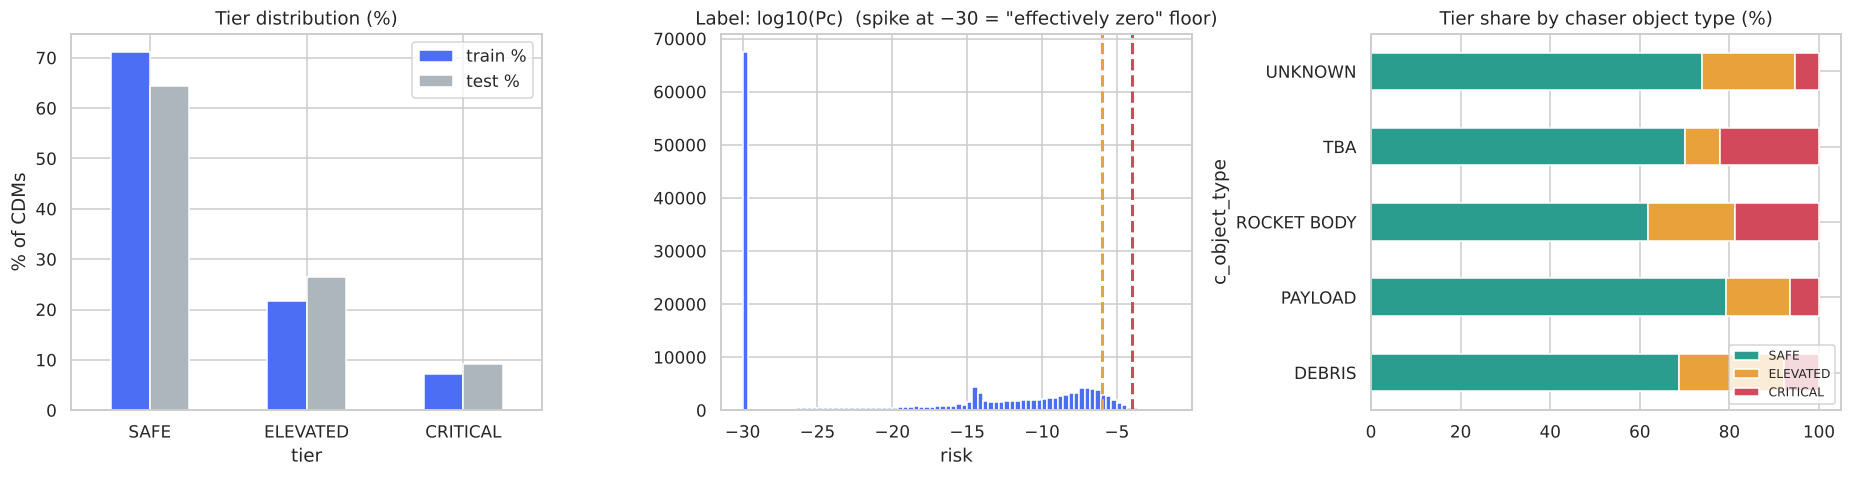

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
(summary[['train %', 'test %']]).plot.bar(ax=ax[0], color=['#4c6ef5', '#adb5bd'], rot=0)
ax[0].set_title('Tier distribution (%)'); ax[0].set_ylabel('% of CDMs')

ax[1].hist(train_raw[LABEL], bins=80, color='#4c6ef5')
for t, c in [(-6, TIER_COLORS['ELEVATED']), (-4, TIER_COLORS['CRITICAL'])]:
    ax[1].axvline(t, color=c, ls='--', lw=2)
ax[1].set_title('Label: log10(Pc)  (spike at −30 = "effectively zero" floor)'); ax[1].set_xlabel('risk')

pd.crosstab(train_raw.c_object_type, train_raw.tier, normalize='index')[TIERS].mul(100).plot.barh(
    stacked=True, ax=ax[2], color=[TIER_COLORS[t] for t in TIERS])
ax[2].set_title('Tier share by chaser object type (%)'); ax[2].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

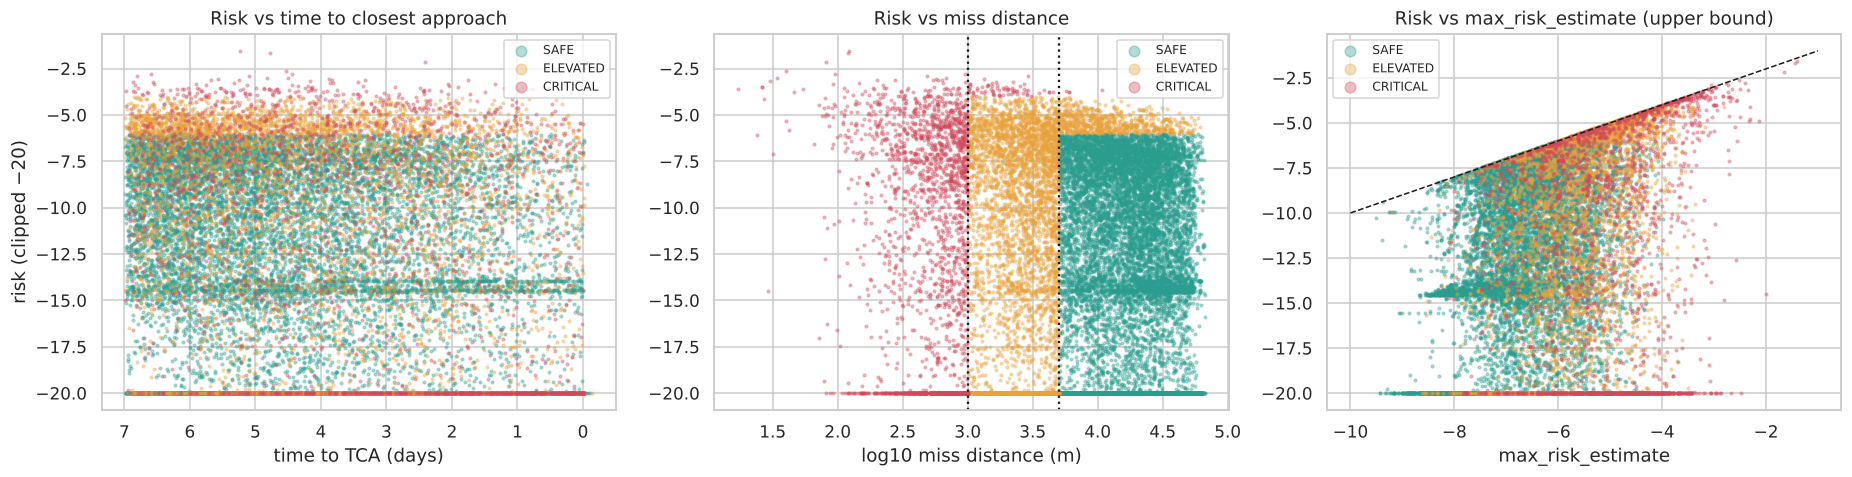

In [5]:
samp = train_raw.sample(30000, random_state=SEED)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for t in TIERS:
    s = samp[samp.tier == t]
    ax[0].scatter(s.time_to_tca, s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
    ax[1].scatter(np.log10(s.miss_distance), s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
    ax[2].scatter(s.max_risk_estimate, s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
ax[0].set(xlabel='time to TCA (days)', ylabel='risk (clipped −20)', title='Risk vs time to closest approach'); ax[0].invert_xaxis()
ax[1].set(xlabel='log10 miss distance (m)', title='Risk vs miss distance')
ax[1].axvline(3, color='k', ls=':'); ax[1].axvline(np.log10(5000), color='k', ls=':')
ax[2].set(xlabel='max_risk_estimate', title='Risk vs max_risk_estimate (upper bound)')
ax[2].plot([-10, -1], [-10, -1], 'k--', lw=1)
for a in ax: a.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

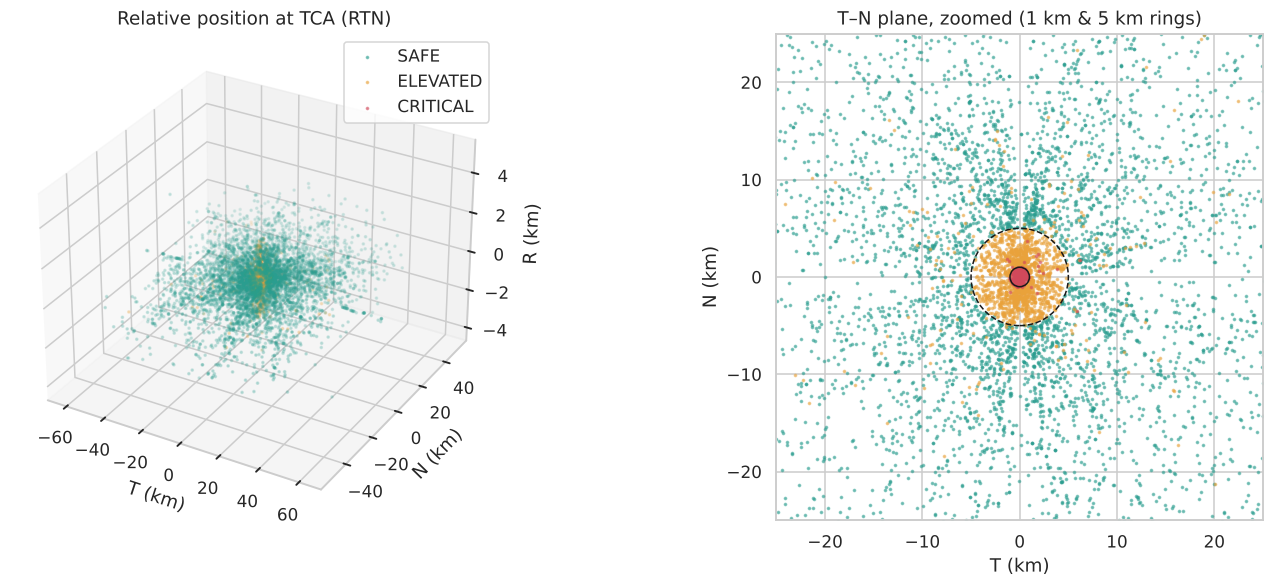

In [6]:
# Encounter geometry in the RTN frame (relative position of chaser w.r.t. target at TCA)
from mpl_toolkits.mplot3d import Axes3D  # noqa
s = train_raw.sample(8000, random_state=1)
fig = plt.figure(figsize=(14, 5.5))
a3 = fig.add_subplot(121, projection='3d')
for t in TIERS:
    q = s[s.tier == t]
    a3.scatter(q.relative_position_t / 1e3, q.relative_position_n / 1e3, q.relative_position_r / 1e3, s=2, c=TIER_COLORS[t], label=t, alpha=.5)
a3.set_xlabel('T (km)'); a3.set_ylabel('N (km)'); a3.set_zlabel('R (km)'); a3.set_title('Relative position at TCA (RTN)'); a3.legend()
a2 = fig.add_subplot(122)
for t in TIERS:
    q = s[s.tier == t]
    a2.scatter(q.relative_position_t / 1e3, q.relative_position_n / 1e3, s=2, c=TIER_COLORS[t], alpha=.5, label=t)
a2.add_patch(plt.Circle((0, 0), 5, fill=False, ls='--', color='k')); a2.add_patch(plt.Circle((0, 0), 1, fill=False, color='k'))
a2.set(xlim=(-25, 25), ylim=(-25, 25), xlabel='T (km)', ylabel='N (km)', title='T–N plane, zoomed (1 km & 5 km rings)'); a2.set_aspect('equal')
plt.tight_layout(); plt.show()

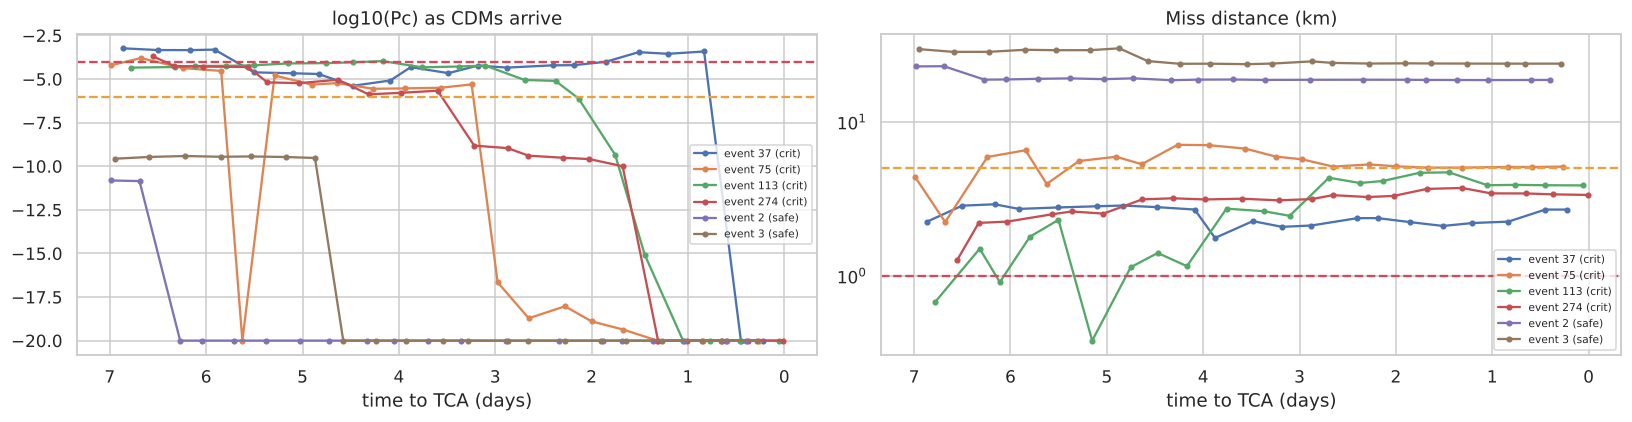

In [7]:
# Risk evolution of a few events that end up Critical vs Safe
ev_crit = train_raw.groupby('event_id').filter(lambda g: (g[LABEL] >= -4).any() and len(g) > 8).event_id.unique()[:4]
ev_safe = train_raw.groupby('event_id').filter(lambda g: (g.tier == 'SAFE').all() and len(g) > 8).event_id.unique()[:2]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for e in list(ev_crit) + list(ev_safe):
    g = train_raw[train_raw.event_id == e].sort_values('time_to_tca', ascending=False)
    lbl = f'event {e} ({"crit" if e in ev_crit else "safe"})'
    ax[0].plot(g.time_to_tca, g[LABEL].clip(-20), marker='o', ms=3, label=lbl)
    ax[1].plot(g.time_to_tca, g.miss_distance / 1e3, marker='o', ms=3, label=lbl)
ax[0].axhline(-4, color=TIER_COLORS['CRITICAL'], ls='--'); ax[0].axhline(-6, color=TIER_COLORS['ELEVATED'], ls='--')
ax[1].axhline(1, color=TIER_COLORS['CRITICAL'], ls='--'); ax[1].axhline(5, color=TIER_COLORS['ELEVATED'], ls='--')
ax[0].set(title='log10(Pc) as CDMs arrive', xlabel='time to TCA (days)'); ax[1].set(title='Miss distance (km)', xlabel='time to TCA (days)', yscale='log')
for a in ax: a.invert_xaxis(); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Look at the test data before choosing features
The test set defines the operating conditions the model must generalise to, so the training data and features should match it.
We only look at test **inputs** here (ranges, missingness, drift). Using test **labels** to pick features would leak the answer.

,train min,train max,test min,test max,train NaN %,test NaN %
AP,0.000000,1.080000e+02,0.000000,1.060000e+02,4.19,5.43
F10,66.000000,2.460000e+02,66.000000,1.820000e+02,4.19,5.43
c_sigma_r,0.927165,6.378136e+07,1.160012,6.378136e+07,0.01,0.02
max_risk_estimate,-9.814175,-1.082442e+00,-10.045951,-1.263444e+00,0.00,0.00
miss_distance,9.000000,6.737300e+04,17.000000,6.592700e+04,0.00,0.00
relative_position_n,-50995.500000,5.099680e+04,-50774.500000,5.052700e+04,0.00,0.00
relative_position_r,-4815.000000,5.284100e+03,-2586.800000,2.406900e+03,0.00,0.00
relative_position_t,-62184.200000,6.218430e+04,-61304.100000,6.128750e+04,0.00,0.00
relative_speed,4.000000,1.713800e+04,58.000000,1.695600e+04,0.00,0.00
t_sigma_r,0.699496,6.378136e+07,0.738897,6.378136e+07,0.00,0.00


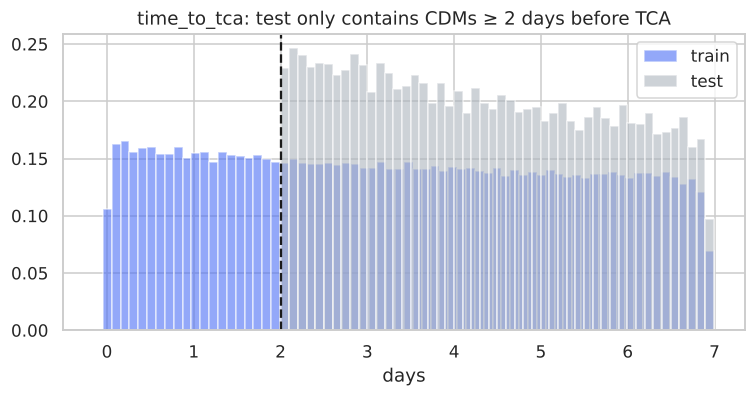

In [8]:
cmp = pd.DataFrame({'train min': train_raw[ALLOWED[1:7] + ALLOWED[8:]].min(), 'train max': train_raw[ALLOWED[1:7] + ALLOWED[8:]].max(),
                    'test min': test_raw[ALLOWED[1:7] + ALLOWED[8:]].min(), 'test max': test_raw[ALLOWED[1:7] + ALLOWED[8:]].max(),
                    'train NaN %': train_raw[ALLOWED].isna().mean().mul(100).round(2), 'test NaN %': test_raw[ALLOWED].isna().mean().mul(100).round(2)}).dropna(subset=['train min'])
display(cmp)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train_raw.time_to_tca, bins=70, alpha=.6, density=True, label='train', color='#4c6ef5')
ax.hist(test_raw.time_to_tca, bins=50, alpha=.6, density=True, label='test', color='#adb5bd')
ax.axvline(2, color='k', ls='--'); ax.set(title='time_to_tca: test only contains CDMs ≥ 2 days before TCA', xlabel='days'); ax.legend(); plt.show()

**Key finding:** every test CDM is ≥ 2 days before closest approach, while train goes down to ~0 days (where uncertainty collapses and risk is much easier).
Training on the late CDMs would teach the model a regime it never sees at test time, so **train is filtered to `time_to_tca ≥ 2`**.
This is also the operationally meaningful framing: a warning ≥ 2 days ahead leaves time to plan a manoeuvre.

The full train set is kept (`train_full`) for the 24-hour warning analysis in section 10.

In [9]:
train_full = train_raw.copy()
train_raw = train_raw[train_raw.time_to_tca >= 2].copy()
print(f'train after filter: {len(train_raw):,} rows, {train_raw.event_id.nunique():,} events')
display(pd.DataFrame({'train(≥2d) %': train_raw.tier.value_counts(normalize=True).mul(100).round(2),
                      'test %': test_raw.tier.value_counts(normalize=True).mul(100).round(2)}).loc[TIERS])

train after filter: 111,939 rows, 11,942 events


,train(≥2d) %,test %
tier,,
SAFE,70.40,64.35
ELEVATED,22.28,26.55
CRITICAL,7.31,9.10


## 4. Feature engineering
Row-level physics features plus **causal** per-event history (only CDMs that arrived *earlier* in the same event — no peeking at later messages).
Rows are ordered from far to near TCA (time_to_tca descending).

In [10]:
OBJ_TYPES = ['DEBRIS', 'PAYLOAD', 'ROCKET BODY', 'UNKNOWN', 'TBA']

def engineer(df):
    d = df.sort_values(['event_id', 'time_to_tca'], ascending=[True, False]).reset_index(drop=True)
    sig_c = d.c_sigma_r.fillna(d.c_sigma_r.median())
    sig_comb = np.sqrt(d.t_sigma_r**2 + sig_c**2)
    f = pd.DataFrame(index=d.index)
    f['time_to_tca'] = d.time_to_tca
    f['log_miss'] = np.log10(d.miss_distance.clip(lower=1))
    f['log_speed'] = np.log10(d.relative_speed.clip(lower=1))
    f['rel_r'], f['rel_t'], f['rel_n'] = d.relative_position_r, d.relative_position_t, d.relative_position_n
    f['log_abs_r'] = np.log10(d.relative_position_r.abs() + 1)
    f['log_abs_t'] = np.log10(d.relative_position_t.abs() + 1)
    f['log_abs_n'] = np.log10(d.relative_position_n.abs() + 1)
    f['log_t_sigma_r'] = np.log10(d.t_sigma_r)
    f['log_c_sigma_r'] = np.log10(sig_c)
    f['log_sigma_comb'] = np.log10(sig_comb)
    f['log_miss_over_sigma'] = f.log_miss - f.log_sigma_comb          # how many sigmas apart (radial proxy)
    f['log_r_over_sigma'] = f.log_abs_r - f.log_sigma_comb
    f['max_risk_estimate'] = d.max_risk_estimate
    f['F10'], f['AP'] = d.F10, d.AP
    for o in OBJ_TYPES:
        f[f'obj_{o.replace(" ", "_")}'] = (d.c_object_type == o).astype(int)
    # ---- causal history within each event ----
    g = d.groupby('event_id')
    f['cdm_index'] = g.cumcount()
    f['mre_prev'] = g.max_risk_estimate.shift(1).fillna(d.max_risk_estimate)
    f['mre_delta'] = d.max_risk_estimate - f.mre_prev
    f['mre_cummax'] = g.max_risk_estimate.cummax()
    f['mre_first'] = g.max_risk_estimate.transform('first')
    f['mre_trend'] = d.max_risk_estimate - f.mre_first
    f['log_miss_prev'] = f.groupby(d.event_id).log_miss.shift(1).fillna(f.log_miss)
    f['log_miss_delta'] = f.log_miss - f.log_miss_prev
    f['log_miss_cummin'] = f.groupby(d.event_id).log_miss.cummin()
    f['log_c_sigma_delta'] = f.log_c_sigma_r - f.groupby(d.event_id).log_c_sigma_r.shift(1).fillna(f.log_c_sigma_r)
    meta = d[['event_id', 'time_to_tca', 'miss_distance', 'c_object_type', 'relative_position_r', 'relative_position_t',
              'relative_position_n', 'max_risk_estimate', 't_sigma_r', 'c_sigma_r', LABEL, 'tier', 'pc_tier']].copy()
    meta['y'] = d[LABEL].clip(lower=Y_FLOOR)      # −30 floor and deep tail → −10 (does not change any tier)
    return f, meta

X_all, M_all = engineer(train_raw)
X_test_all, M_test = engineer(test_raw)
print('engineered features:', X_all.shape[1]); X_all.describe().T.head(12)

engineered features: 32


,count,mean,std,min,25%,50%,75%,max
time_to_tca,111939.0,4.424304,1.425904,2.000014,3.185255,4.399526,5.658008,6.993832
log_miss,111939.0,3.978946,0.550514,0.954243,3.672744,4.093842,4.403103,4.828486
log_speed,111939.0,3.951184,0.331828,0.602060,3.867821,4.088349,4.161008,4.232666
rel_r,111939.0,-39.957608,637.685527,-4815.000000,-298.100000,-26.100000,235.700000,5284.100000
rel_t,111939.0,8.813408,14826.735318,-61287.600000,-5854.350000,0.200000,5808.300000,61304.000000
rel_n,111939.0,160.754146,16067.884603,-50995.500000,-6870.900000,49.500000,7450.850000,50994.200000
log_abs_r,111939.0,2.365254,0.553685,0.000000,2.057666,2.426023,2.721605,3.723053
log_abs_t,111939.0,3.614333,0.739725,0.000000,3.207284,3.765959,4.174234,4.787496
log_abs_n,111939.0,3.737587,0.642578,0.041393,3.384694,3.854215,4.222943,4.707540
log_t_sigma_r,111939.0,0.859494,0.903156,-0.155215,0.594031,0.762441,0.914455,7.804694


## 5. Feature selection
Three filters, in order:
1. **Relevance** — Pearson r with the target `log10(Pc)` on train: keep |r| ≥ 0.05 and p < 0.001.
2. **Test-set check** — two-sample KS statistic between train and test feature distributions: drop features whose distribution shifts strongly (KS > 0.25), since what is learnt from them won't transfer.
3. **Redundancy** — for feature pairs with |r| > 0.95, keep the one more correlated with the target.

In [11]:
y_all = M_all.y.values
rows = []
for c in X_all.columns:
    x = X_all[c].values; m = ~np.isnan(x)
    if np.nanstd(x) == 0: rows.append((c, 0, 1, np.nan)); continue
    r, p = pearsonr(x[m], y_all[m])
    ks = ks_2samp(X_all[c].dropna(), X_test_all[c].dropna()).statistic
    rows.append((c, r, p, ks))
fs = pd.DataFrame(rows, columns=['feature', 'pearson_r', 'p_value', 'ks_train_vs_test']).set_index('feature')
fs['abs_r'] = fs.pearson_r.abs()
fs['relevant'] = (fs.abs_r >= 0.05) & (fs.p_value < 1e-3)
fs['stable_on_test'] = fs.ks_train_vs_test <= 0.25
fs = fs.sort_values('abs_r', ascending=False)

cand = fs[fs.relevant & fs.stable_on_test].index.tolist()
corr = X_all[cand].corr().abs()
dropped_redundant = set()
for i, a in enumerate(cand):
    for b in cand[i + 1:]:
        if a in dropped_redundant or b in dropped_redundant: continue
        if corr.loc[a, b] > 0.95:
            dropped_redundant.add(b if fs.abs_r[a] >= fs.abs_r[b] else a)
SELECTED = [c for c in cand if c not in dropped_redundant]
fs['selected'] = fs.index.isin(SELECTED)
print(f'{len(SELECTED)} selected features:', SELECTED)
print('dropped (redundant):', sorted(dropped_redundant))
print('dropped (drift on test):', fs[fs.relevant & ~fs.stable_on_test].index.tolist())
display(fs.round(4))

19 selected features: ['max_risk_estimate', 'mre_cummax', 'mre_first', 'log_miss', 'log_miss_prev', 'log_miss_cummin', 'log_abs_r', 'log_abs_n', 'time_to_tca', 'cdm_index', 'log_abs_t', 'log_r_over_sigma', 'mre_trend', 'log_miss_over_sigma', 'obj_PAYLOAD', 'log_c_sigma_r', 'mre_delta', 'obj_UNKNOWN', 'log_t_sigma_r']
dropped (redundant): ['mre_prev']
dropped (drift on test): []


,pearson_r,p_value,ks_train_vs_test,abs_r,relevant,stable_on_test,selected
feature,,,,,,,
max_risk_estimate,0.3932,0.0000,0.0665,0.3932,True,True,True
mre_prev,0.3651,0.0000,0.0680,0.3651,True,True,False
mre_cummax,0.3379,0.0000,0.0784,0.3379,True,True,True
mre_first,0.3077,0.0000,0.0826,0.3077,True,True,True
log_miss,-0.2715,0.0000,0.0649,0.2715,True,True,True
log_miss_prev,-0.2649,0.0000,0.0632,0.2649,True,True,True
log_miss_cummin,-0.2649,0.0000,0.0604,0.2649,True,True,True
log_abs_r,-0.2642,0.0000,0.0682,0.2642,True,True,True
log_abs_n,-0.2512,0.0000,0.0481,0.2512,True,True,True


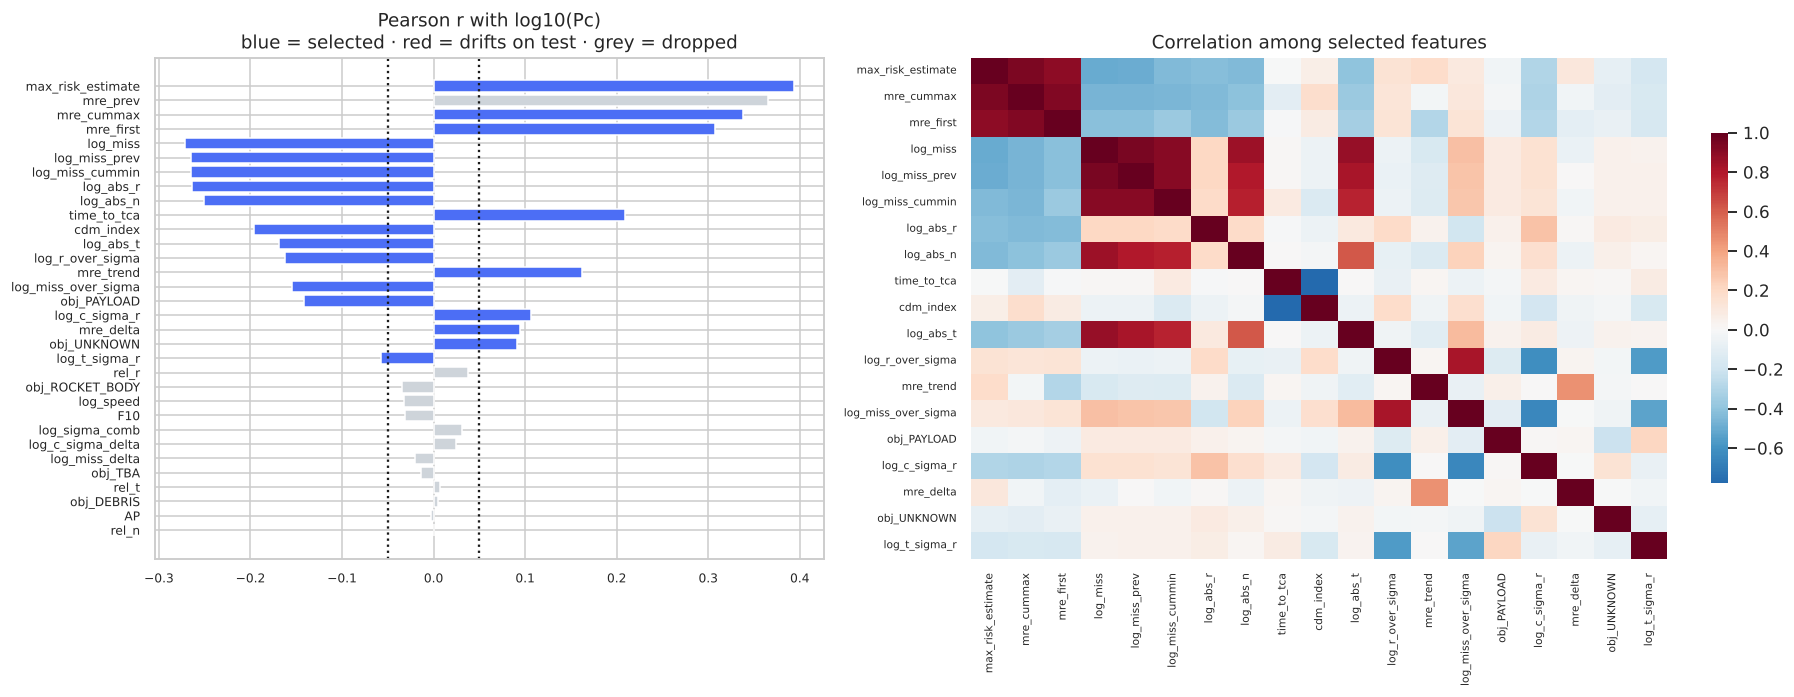

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
cols = np.where(fs.selected, '#4c6ef5', np.where(~fs.stable_on_test, '#d1495b', '#ced4da'))
ax[0].barh(fs.index[::-1], fs.pearson_r[::-1], color=cols[::-1])
ax[0].axvline(0.05, ls=':', c='k'); ax[0].axvline(-0.05, ls=':', c='k')
ax[0].set_title('Pearson r with log10(Pc)\nblue = selected · red = drifts on test · grey = dropped'); ax[0].tick_params(labelsize=8)
sns.heatmap(X_all[SELECTED].corr(), cmap='RdBu_r', center=0, ax=ax[1], cbar_kws={'shrink': .7}, xticklabels=True, yticklabels=True)
ax[1].set_title('Correlation among selected features'); ax[1].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

## 6. Train/validation split, scaling and PCA (99 % variance)
Split **by event** (GroupShuffleSplit) so CDMs from one event never land in both train and validation.
Imputer, scaler and PCA are fit on the training split only.

PCA: 19 features → 13 components retain 0.9908 of variance


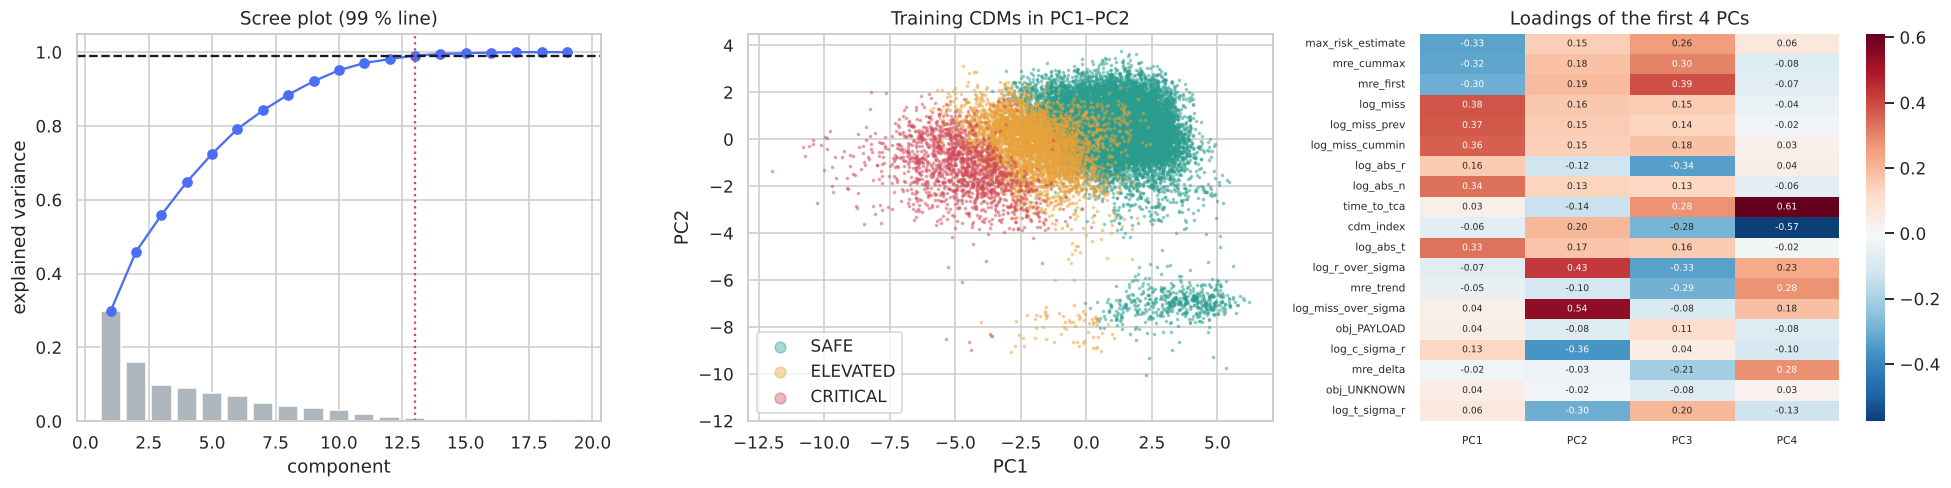

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(X_all, y_all, groups=M_all.event_id))
X_tr_raw, X_va_raw, X_te_raw = X_all.iloc[tr_idx][SELECTED], X_all.iloc[va_idx][SELECTED], X_test_all[SELECTED]
M_tr, M_va = M_all.iloc[tr_idx].reset_index(drop=True), M_all.iloc[va_idx].reset_index(drop=True)
y_tr, y_va, y_te = M_tr.y.values, M_va.y.values, M_test.y.values

imputer = SimpleImputer(strategy='median').fit(X_tr_raw)
scaler = StandardScaler().fit(imputer.transform(X_tr_raw))
prep = lambda X: scaler.transform(imputer.transform(X))
Z_tr, Z_va, Z_te = prep(X_tr_raw), prep(X_va_raw), prep(X_te_raw)

pca = PCA(n_components=0.99, svd_solver='full', random_state=SEED).fit(Z_tr)
P_tr, P_va, P_te = pca.transform(Z_tr), pca.transform(Z_va), pca.transform(Z_te)
print(f'PCA: {len(SELECTED)} features → {pca.n_components_} components retain {pca.explained_variance_ratio_.sum():.4f} of variance')

full_pca = PCA().fit(Z_tr)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
cum = np.cumsum(full_pca.explained_variance_ratio_)
ax[0].bar(range(1, len(cum) + 1), full_pca.explained_variance_ratio_, color='#adb5bd')
ax[0].plot(range(1, len(cum) + 1), cum, 'o-', c='#4c6ef5'); ax[0].axhline(.99, c='k', ls='--')
ax[0].axvline(pca.n_components_, c=TIER_COLORS['CRITICAL'], ls=':')
ax[0].set(title='Scree plot (99 % line)', xlabel='component', ylabel='explained variance')
sidx = np.random.RandomState(0).choice(len(P_tr), 20000, replace=False)
tiers_tr = M_tr.tier.values
for t in TIERS:
    m = sidx[tiers_tr[sidx] == t]
    ax[1].scatter(P_tr[m, 0], P_tr[m, 1], s=2, alpha=.4, c=TIER_COLORS[t], label=t)
ax[1].set(title='Training CDMs in PC1–PC2', xlabel='PC1', ylabel='PC2'); ax[1].legend(markerscale=5)
load = pd.DataFrame(pca.components_[:4].T, index=SELECTED, columns=[f'PC{i+1}' for i in range(4)])
sns.heatmap(load, cmap='RdBu_r', center=0, ax=ax[2], annot=True, fmt='.2f', annot_kws={'size': 6}); ax[2].tick_params(labelsize=7)
ax[2].set_title('Loadings of the first 4 PCs')
plt.tight_layout(); plt.show()

## 7. Evaluation framework (challenge metrics)
Every model outputs a predicted `log10(Pc)`; the tier is then `tier_from(pred_risk, miss_distance)`.

Reported metrics:
- **Critical recall** (most important: a missed manoeuvre is the costly error) and Critical precision (false-alarm load)
- **Macro-F1** over the 3 tiers
- **Pc-tier macro-F1** — tiers from Pc only, which isolates the part the model actually has to learn (miss-distance rules are exact)
- **High-risk recall** — share of true Pc ≥ 1e-6 CDMs caught
- **RMSE** of log10(Pc) (label floored at −10) on all rows and on the high-risk rows (true risk ≥ −6)

**Baseline** (what an operator gets with no ML): use `max_risk_estimate` (the conservative upper-bound Pc provided in the CDM) directly as the Pc.

In [14]:
RESULTS = {}

def evaluate(name, pred_risk, meta, split='val', store=True, verbose=False):
    pred_risk = np.asarray(pred_risk, dtype=float)
    y_true_t, y_pred_t = meta.tier.values, tier_from(pred_risk, meta.miss_distance.values)
    pc_true, pc_pred = meta.pc_tier.values, pc_tier(pred_risk)
    hr = meta.y.values >= -6
    res = {
        'critical_recall': recall_score(y_true_t, y_pred_t, labels=['CRITICAL'], average='macro', zero_division=0),
        'critical_precision': precision_score(y_true_t, y_pred_t, labels=['CRITICAL'], average='macro', zero_division=0),
        'macro_f1': f1_score(y_true_t, y_pred_t, labels=TIERS, average='macro'),
        'pc_macro_f1': f1_score(pc_true, pc_pred, labels=TIERS, average='macro'),
        'pc_critical_recall': recall_score(pc_true, pc_pred, labels=['CRITICAL'], average='macro', zero_division=0),
        'highrisk_recall': (pred_risk[hr] >= -6).mean() if hr.any() else np.nan,
        'rmse': mean_squared_error(meta.y.values, np.clip(pred_risk, Y_FLOOR, 0)) ** .5,
        'rmse_highrisk': mean_squared_error(meta.y.values[hr], np.clip(pred_risk[hr], Y_FLOOR, 0)) ** .5 if hr.any() else np.nan,
    }
    if store: RESULTS[(name, split)] = res
    if verbose: print(name, split, {k: round(v, 4) for k, v in res.items()})
    return res

def plot_cms(preds, meta, title_suffix=''):
    n = len(preds); fig, ax = plt.subplots(1, n, figsize=(4.6 * n, 4))
    ax = np.atleast_1d(ax)
    for a, (nm, pr) in zip(ax, preds.items()):
        cm = confusion_matrix(meta.tier.values, tier_from(pr, meta.miss_distance.values), labels=TIERS)
        cmn = cm / cm.sum(1, keepdims=True)
        sns.heatmap(cmn, annot=np.array([[f'{cmn[i,j]:.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]), fmt='',
                    cmap='Blues', xticklabels=TIERS, yticklabels=TIERS, cbar=False, ax=a, annot_kws={'size': 8})
        a.set(title=f'{nm}{title_suffix}', xlabel='predicted', ylabel='true')
    plt.tight_layout(); plt.show()

# Sample weights: high-risk CDMs are rare but matter most
def weights(y): return 1 + 4 * (y >= -6) + 10 * (y >= -4)
w_tr = weights(y_tr)

VAL_PRED, TEST_PRED = {}, {}
VAL_PRED['Baseline (max_risk_estimate)'] = M_va.max_risk_estimate.values
TEST_PRED['Baseline (max_risk_estimate)'] = M_test.max_risk_estimate.values
evaluate('Baseline (max_risk_estimate)', VAL_PRED['Baseline (max_risk_estimate)'], M_va, verbose=True);

Baseline (max_risk_estimate) val {'critical_recall': 1.0, 'critical_precision': 0.9261, 'macro_f1': 0.8368, 'pc_macro_f1': 0.5524, 'pc_critical_recall': 1.0, 'highrisk_recall': np.float64(1.0), 'rmse': 3.1155, 'rmse_highrisk': 0.5341}


## 8. Models
### 8.1 Elliptic Envelope — unsupervised anomaly detection
Fit a robust Gaussian envelope on the PCA features of **Pc-safe** CDMs only. CDMs far outside the envelope are anomalous → potentially high risk.
The Mahalanobis score is mapped to a pseudo-log10(Pc) by isotonic calibration on the training split, so it can go through the same tier rule.

In [15]:
from sklearn.isotonic import IsotonicRegression
t0 = time.time()
safe_mask = y_tr < -6
fit_idx = np.random.RandomState(SEED).choice(np.where(safe_mask)[0], min(30000, safe_mask.sum()), replace=False)
ee = EllipticEnvelope(contamination=0.02, support_fraction=0.9, random_state=SEED).fit(P_tr[fit_idx])
score = lambda P: -ee.decision_function(P)          # higher = more anomalous
s_tr, s_va, s_te = score(P_tr), score(P_va), score(P_te)
print('Elliptic envelope ROC-AUC (val) for detecting Pc ≥ 1e-6:', round(roc_auc_score(y_va >= -6, s_va), 4))
iso = IsotonicRegression(out_of_bounds='clip').fit(s_tr, y_tr)
VAL_PRED['Elliptic Envelope'], TEST_PRED['Elliptic Envelope'] = iso.predict(s_va), iso.predict(s_te)
evaluate('Elliptic Envelope', VAL_PRED['Elliptic Envelope'], M_va, verbose=True); print(f'{time.time()-t0:.1f}s')

Elliptic envelope ROC-AUC (val) for detecting Pc ≥ 1e-6: 0.6225


Elliptic Envelope val {'critical_recall': 0.962, 'critical_precision': 1.0, 'macro_f1': 0.9564, 'pc_macro_f1': 0.3184, 'pc_critical_recall': 0.0, 'highrisk_recall': np.float64(0.0), 'rmse': 1.6323, 'rmse_highrisk': 3.7892}
5.2s


### 8.2 Classical ML regressors on PCA features
Ridge (linear), Random Forest, XGBoost, LightGBM — all predict log10(Pc) with risk-weighted samples.
A LightGBM on the raw selected features (no PCA) is included as an ablation: trees often do better without rotation.

In [16]:
classical = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=5, max_features=0.6, n_jobs=-1, random_state=SEED),
    'XGBoost': xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                                tree_method='hist', n_jobs=-1, random_state=SEED, early_stopping_rounds=50),
    'LightGBM': lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, random_state=SEED, verbose=-1),
}
for nm, mdl in classical.items():
    t0 = time.time()
    if nm == 'XGBoost':
        mdl.fit(P_tr, y_tr, sample_weight=w_tr, eval_set=[(P_va, y_va)], verbose=False)
    elif nm == 'LightGBM':
        mdl.fit(P_tr, y_tr, sample_weight=w_tr, eval_set=[(P_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        mdl.fit(P_tr, y_tr, sample_weight=w_tr)
    VAL_PRED[nm], TEST_PRED[nm] = mdl.predict(P_va), mdl.predict(P_te)
    evaluate(nm, VAL_PRED[nm], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

# Ablation: LightGBM on raw selected features (no PCA)
t0 = time.time()
lgb_raw = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_raw.fit(Z_tr, y_tr, sample_weight=w_tr, eval_set=[(Z_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
VAL_PRED['LightGBM (no PCA)'], TEST_PRED['LightGBM (no PCA)'] = lgb_raw.predict(Z_va), lgb_raw.predict(Z_te)
evaluate('LightGBM (no PCA)', VAL_PRED['LightGBM (no PCA)'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

Ridge val {'critical_recall': 0.9689, 'critical_precision': 0.9871, 'macro_f1': 0.9589, 'pc_macro_f1': 0.5767, 'pc_critical_recall': 0.3033, 'highrisk_recall': np.float64(0.3527), 'rmse': 1.4602, 'rmse_highrisk': 1.3123}
   0.2s


Random Forest val {'critical_recall': 0.9702, 'critical_precision': 0.9974, 'macro_f1': 0.9678, 'pc_macro_f1': 0.6595, 'pc_critical_recall': 0.3033, 'highrisk_recall': np.float64(0.5013), 'rmse': 1.0426, 'rmse_highrisk': 1.3285}
   34.8s


XGBoost val {'critical_recall': 0.9766, 'critical_precision': 0.9923, 'macro_f1': 0.9706, 'pc_macro_f1': 0.7038, 'pc_critical_recall': 0.4016, 'highrisk_recall': np.float64(0.5594), 'rmse': 1.0186, 'rmse_highrisk': 1.2563}
   5.3s


LightGBM val {'critical_recall': 0.9728, 'critical_precision': 0.9935, 'macro_f1': 0.97, 'pc_macro_f1': 0.6958, 'pc_critical_recall': 0.4016, 'highrisk_recall': np.float64(0.5647), 'rmse': 1.0099, 'rmse_highrisk': 1.2061}
   12.2s


LightGBM (no PCA) val {'critical_recall': 0.9804, 'critical_precision': 0.9929, 'macro_f1': 0.9733, 'pc_macro_f1': 0.7521, 'pc_critical_recall': 0.5082, 'highrisk_recall': np.float64(0.6457), 'rmse': 0.9446, 'rmse_highrisk': 1.0229}
   9.2s


**Improvement 1 — ablation:** same LightGBM (no PCA), trained with the label floored at −20 (v1) vs −10 (now). Validation only.

In [17]:
abl = {}
for fl in (-20.0, Y_FLOOR):
    yt, yv = M_tr[LABEL].clip(lower=fl).values, M_va[LABEL].clip(lower=fl).values
    mdl_ab = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, random_state=SEED, verbose=-1)
    mdl_ab.fit(Z_tr, yt, sample_weight=weights(yt), eval_set=[(Z_va, yv)], callbacks=[lgb.early_stopping(100, verbose=False)])
    abl[f'label floor {fl:.0f}'] = evaluate('ablation', mdl_ab.predict(Z_va), M_va, store=False)
display(pd.DataFrame(abl).T[['macro_f1', 'pc_macro_f1', 'pc_critical_recall', 'highrisk_recall', 'rmse_highrisk']].round(4))

,macro_f1,pc_macro_f1,pc_critical_recall,highrisk_recall,rmse_highrisk
label floor -20,0.9734,0.7658,0.6066,0.6105,1.5221
label floor -10,0.9733,0.7521,0.5082,0.6457,1.0229


### 8.3 Direct tier classifier (LightGBM, class-balanced)
Instead of regressing Pc, classify the **Pc-tier** directly, then combine with the exact miss-distance rule.
The predicted class probabilities are turned into an expected log10(Pc) only so the same evaluation applies.

In [18]:
t0 = time.time()
cls_map = {t: i for i, t in enumerate(TIERS)}
lgb_cls = lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=63, class_weight='balanced',
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_cls.fit(P_tr, M_tr.pc_tier.map(cls_map), eval_set=[(P_va, M_va.pc_tier.map(cls_map))],
            callbacks=[lgb.early_stopping(100, verbose=False)])
def cls_to_risk(proba):   # representative log10(Pc) per predicted class
    return np.array([-10.0, -5.0, -3.0])[proba.argmax(1)]
VAL_PRED['LightGBM classifier'] = cls_to_risk(lgb_cls.predict_proba(P_va))
TEST_PRED['LightGBM classifier'] = cls_to_risk(lgb_cls.predict_proba(P_te))
evaluate('LightGBM classifier', VAL_PRED['LightGBM classifier'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

LightGBM classifier val {'critical_recall': 0.9797, 'critical_precision': 0.9917, 'macro_f1': 0.9694, 'pc_macro_f1': 0.7624, 'pc_critical_recall': 0.5328, 'highrisk_recall': np.float64(0.8135), 'rmse': 1.5093, 'rmse_highrisk': 1.9928}
   23.6s


### 8.4 Deep learning — MLP on PCA features (PyTorch)

In [19]:
def train_torch(model, make_batches, val_fn, epochs=25, lr=2e-3, patience=5, name='model'):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    best, best_state, bad, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train(); tl = []
        for loss_fn in make_batches():
            opt.zero_grad(); loss = loss_fn(model); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl.append(loss.item())
        vl = val_fn(model); sched.step(vl); hist.append((np.mean(tl), vl))
        if vl < best - 1e-4: best, best_state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    print(f'{name}: {len(hist)} epochs, best val weighted-MSE {best:.4f}')
    return hist

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.2),
                                 nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.1),
                                 nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Ptr_t, ytr_t, wtr_t, Pva_t, yva_t, wva_t = T(P_tr), T(y_tr), T(w_tr), T(P_va), T(y_va), T(weights(y_va))

def mlp_batches(bs=1024):
    perm = torch.randperm(len(Ptr_t))
    for i in range(0, len(perm), bs):
        b = perm[i:i + bs]
        yield lambda m, b=b: (wtr_t[b] * (m(Ptr_t[b]) - ytr_t[b]) ** 2).mean()

def mlp_val(m):
    m.eval()
    with torch.no_grad(): return (wva_t * (m(Pva_t) - yva_t) ** 2).mean().item()

t0 = time.time()
torch.manual_seed(SEED)
mlp = MLP(P_tr.shape[1])
hist_mlp = train_torch(mlp, mlp_batches, mlp_val, epochs=40, name='MLP')
mlp.eval()
with torch.no_grad():
    VAL_PRED['MLP'], TEST_PRED['MLP'] = mlp(Pva_t).numpy(), mlp(T(P_te)).numpy()
evaluate('MLP', VAL_PRED['MLP'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

MLP: 19 epochs, best val weighted-MSE 1.2553


MLP val {'critical_recall': 0.9943, 'critical_precision': 0.9825, 'macro_f1': 0.9738, 'pc_macro_f1': 0.8067, 'pc_critical_recall': 0.8361, 'highrisk_recall': np.float64(0.7405), 'rmse': 1.0215, 'rmse_highrisk': 0.7734}
   9.5s


### 8.5 Sequence models — GRU (RNN) and causal 1D-CNN
Each event is a time series of CDMs. These models read the PCA features of **all CDMs received so far** in the event and predict log10(Pc) for the current one (many-to-many).
The GRU is unidirectional and the CNN uses left-only (causal) padding, so neither sees future messages.

In [20]:
def to_sequences(P, meta, y=None):
    ev = meta.event_id.values
    starts = np.r_[0, np.where(ev[1:] != ev[:-1])[0] + 1]; ends = np.r_[starts[1:], len(ev)]
    L = (ends - starts).max(); n = len(starts); d = P.shape[1]
    Xs, Ys, Ms, Ws = np.zeros((n, L, d), np.float32), np.zeros((n, L), np.float32), np.zeros((n, L), np.float32), np.zeros((n, L), np.float32)
    for k, (s, e) in enumerate(zip(starts, ends)):
        Xs[k, :e - s] = P[s:e]; Ms[k, :e - s] = 1
        if y is not None: Ys[k, :e - s] = y[s:e]; Ws[k, :e - s] = weights(y[s:e])
    return T(Xs), T(Ys), T(Ms), T(Ws), (starts, ends)

# meta frames are already sorted by event then time_to_tca desc (engineer()), splits preserve that order
S_tr = to_sequences(P_tr, M_tr, y_tr); S_va = to_sequences(P_va, M_va, y_va); S_te = to_sequences(P_te, M_test, y_te)
print('sequence tensors:', S_tr[0].shape, S_va[0].shape, S_te[0].shape)

class GRUNet(nn.Module):
    def __init__(self, d, h=64):
        super().__init__()
        self.inp = nn.Linear(d, h); self.gru = nn.GRU(h, h, num_layers=2, batch_first=True, dropout=.1)
        self.head = nn.Sequential(nn.Linear(h + d, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        o, _ = self.gru(torch.relu(self.inp(x)))
        return self.head(torch.cat([o, x], -1)).squeeze(-1)

class CausalCNN(nn.Module):
    def __init__(self, d, c=64, k=3):
        super().__init__()
        self.k = k
        self.convs = nn.ModuleList([nn.Conv1d(d, c, k, dilation=1), nn.Conv1d(c, c, k, dilation=2), nn.Conv1d(c, c, k, dilation=4)])
        self.head = nn.Sequential(nn.Linear(c + d, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        h = x.transpose(1, 2)
        for i, conv in enumerate(self.convs):
            pad = (self.k - 1) * conv.dilation[0]
            h = torch.relu(conv(nn.functional.pad(h, (pad, 0))))   # left-pad only → causal
        return self.head(torch.cat([h.transpose(1, 2), x], -1)).squeeze(-1)

def seq_batches(S, bs=128):
    X, Y, M, W, _ = S
    def gen():
        perm = torch.randperm(len(X))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            yield lambda m, b=b: ((m(X[b]) - Y[b]) ** 2 * W[b] * M[b]).sum() / M[b].sum()
    return gen

def seq_val(S):
    X, Y, M, W, _ = S
    def f(m):
        m.eval()
        with torch.no_grad(): return (((m(X) - Y) ** 2 * W * M).sum() / M.sum()).item()
    return f

def seq_predict(m, S):
    m.eval()
    with torch.no_grad(): out = m(S[0]).numpy()
    starts, ends = S[4]
    return np.concatenate([out[k, :e - s] for k, (s, e) in enumerate(zip(starts, ends))])

for nm, cls in [('GRU (RNN)', GRUNet), ('1D-CNN (causal)', CausalCNN)]:
    t0 = time.time(); torch.manual_seed(SEED)
    net = cls(P_tr.shape[1])
    train_torch(net, seq_batches(S_tr), seq_val(S_va), epochs=40, lr=2e-3, patience=6, name=nm)
    VAL_PRED[nm], TEST_PRED[nm] = seq_predict(net, S_va), seq_predict(net, S_te)
    evaluate(nm, VAL_PRED[nm], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

sequence tensors: torch.Size([9553, 17, 13]) torch.Size([2389, 16, 13]) torch.Size([2167, 17, 13])


GRU (RNN): 40 epochs, best val weighted-MSE 1.1410


GRU (RNN) val {'critical_recall': 0.9804, 'critical_precision': 0.9936, 'macro_f1': 0.9744, 'pc_macro_f1': 0.7831, 'pc_critical_recall': 0.5574, 'highrisk_recall': np.float64(0.7906), 'rmse': 0.953, 'rmse_highrisk': 0.8102}
   59.6s


1D-CNN (causal): 40 epochs, best val weighted-MSE 1.2453


1D-CNN (causal) val {'critical_recall': 0.9816, 'critical_precision': 0.9917, 'macro_f1': 0.9725, 'pc_macro_f1': 0.761, 'pc_critical_recall': 0.5246, 'highrisk_recall': np.float64(0.6931), 'rmse': 0.9788, 'rmse_highrisk': 0.8593}
   22.2s


### 8.6 Ensemble
Average of the three best regressors on validation macro-F1.

In [21]:
val_tbl = pd.DataFrame({k[0]: v for k, v in RESULTS.items() if k[1] == 'val'}).T
reg_models = [m for m in val_tbl.index if m not in ('Baseline (max_risk_estimate)', 'Elliptic Envelope', 'LightGBM classifier')]
top3 = val_tbl.loc[reg_models].sort_values('macro_f1', ascending=False).index[:3].tolist()
print('ensemble of:', top3)
VAL_PRED['Ensemble (top-3)'] = np.mean([VAL_PRED[m] for m in top3], 0)
TEST_PRED['Ensemble (top-3)'] = np.mean([TEST_PRED[m] for m in top3], 0)
evaluate('Ensemble (top-3)', VAL_PRED['Ensemble (top-3)'], M_va, verbose=True);

ensemble of: ['GRU (RNN)', 'MLP', 'LightGBM (no PCA)']


Ensemble (top-3) val {'critical_recall': 0.9867, 'critical_precision': 0.9936, 'macro_f1': 0.9756, 'pc_macro_f1': 0.7985, 'pc_critical_recall': 0.6148, 'highrisk_recall': np.float64(0.7219), 'rmse': 0.9394, 'rmse_highrisk': 0.8139}


## 9. Results
### 9.1 Validation (model selection) and test (final, unseen events)
The best model is chosen on **validation** macro-F1; test numbers are reported once for every model, untouched by any tuning.

In [22]:
for nm, pr in TEST_PRED.items():
    evaluate(nm, pr, M_test, split='test')
res = pd.DataFrame(RESULTS).T
val_tbl, test_tbl = res.xs('val', level=1), res.xs('test', level=1)
BEST = val_tbl.drop('Baseline (max_risk_estimate)').macro_f1.idxmax()
print('Selected on validation:', BEST)
cols_show = ['critical_recall', 'critical_precision', 'macro_f1', 'pc_macro_f1', 'pc_critical_recall', 'highrisk_recall', 'rmse', 'rmse_highrisk']
print('\nVALIDATION'); display(val_tbl[cols_show].sort_values('macro_f1', ascending=False).style.format('{:.3f}').background_gradient(cmap='Greens', subset=['macro_f1', 'critical_recall', 'pc_macro_f1']))
print('TEST'); display(test_tbl[cols_show].sort_values('macro_f1', ascending=False).style.format('{:.3f}').background_gradient(cmap='Greens', subset=['macro_f1', 'critical_recall', 'pc_macro_f1']))
test_tbl.to_csv(f'{OUT_DIR}/test_metrics.csv')

Selected on validation: Ensemble (top-3)

VALIDATION


,critical_recall,critical_precision,macro_f1,pc_macro_f1,pc_critical_recall,highrisk_recall,rmse,rmse_highrisk
Ensemble (top-3),0.987,0.994,0.976,0.798,0.615,0.722,0.939,0.814
GRU (RNN),0.980,0.994,0.974,0.783,0.557,0.791,0.953,0.810
MLP,0.994,0.982,0.974,0.807,0.836,0.741,1.021,0.773
LightGBM (no PCA),0.980,0.993,0.973,0.752,0.508,0.646,0.945,1.023
1D-CNN (causal),0.982,0.992,0.972,0.761,0.525,0.693,0.979,0.859
XGBoost,0.977,0.992,0.971,0.704,0.402,0.559,1.019,1.256
LightGBM,0.973,0.994,0.970,0.696,0.402,0.565,1.010,1.206
LightGBM classifier,0.980,0.992,0.969,0.762,0.533,0.814,1.509,1.993
Random Forest,0.970,0.997,0.968,0.660,0.303,0.501,1.043,1.328
Ridge,0.969,0.987,0.959,0.577,0.303,0.353,1.460,1.312


TEST


,critical_recall,critical_precision,macro_f1,pc_macro_f1,pc_critical_recall,highrisk_recall,rmse,rmse_highrisk
Ensemble (top-3),0.982,0.996,0.976,0.832,0.708,0.749,0.923,0.716
GRU (RNN),0.981,0.994,0.975,0.822,0.631,0.803,0.933,0.713
MLP,0.990,0.986,0.974,0.824,0.841,0.771,1.005,0.671
1D-CNN (causal),0.982,0.987,0.973,0.782,0.605,0.721,0.973,0.773
LightGBM (no PCA),0.978,0.995,0.972,0.782,0.592,0.648,0.942,0.923
LightGBM classifier,0.978,0.989,0.971,0.761,0.511,0.832,1.505,1.904
LightGBM,0.973,0.993,0.968,0.686,0.339,0.563,1.013,1.132
XGBoost,0.971,0.991,0.967,0.679,0.335,0.554,1.019,1.130
Random Forest,0.966,0.997,0.964,0.643,0.275,0.493,1.066,1.228
Ridge,0.963,0.991,0.956,0.575,0.292,0.361,1.495,1.353


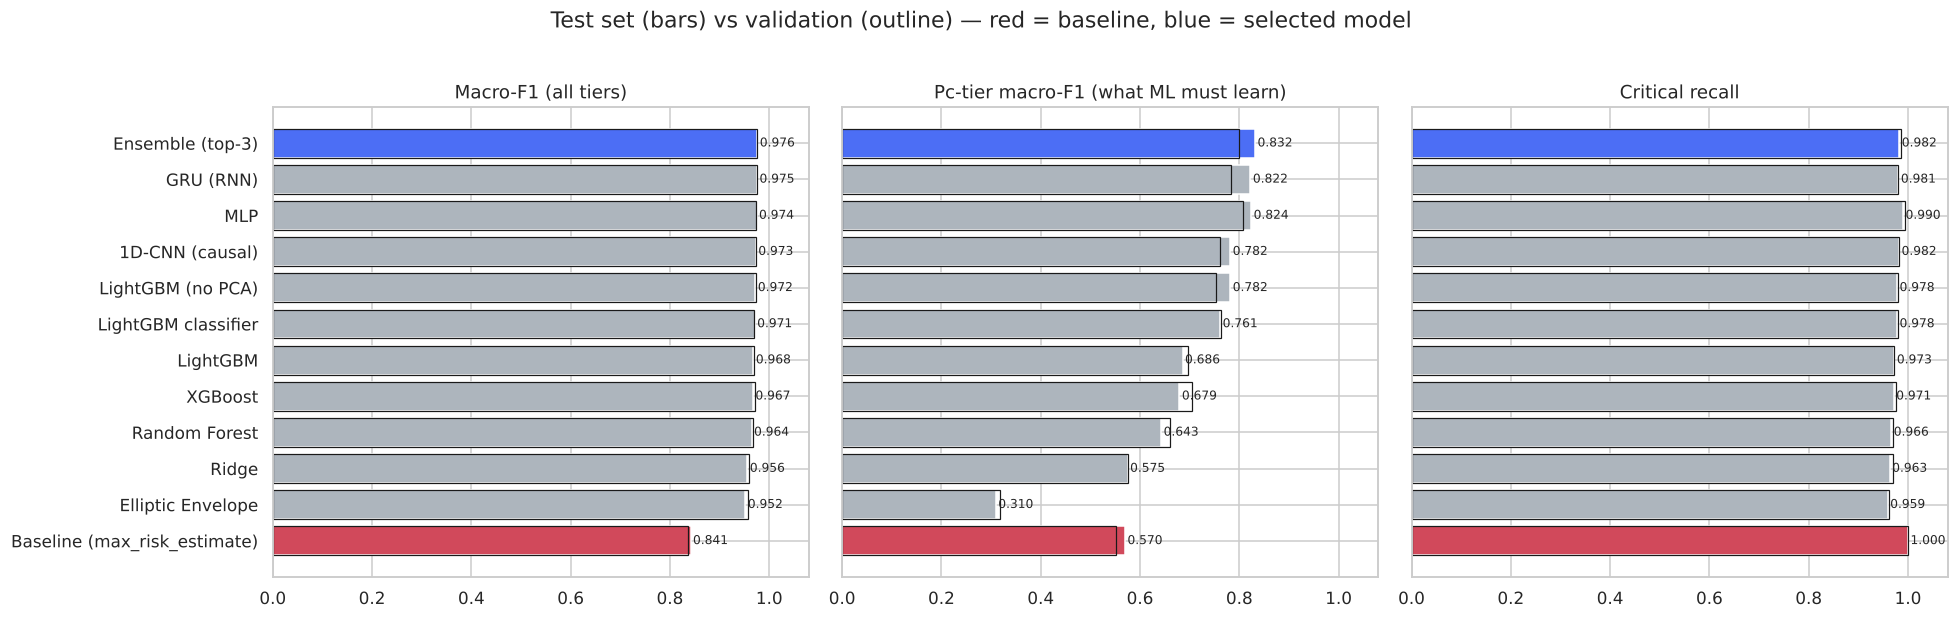

In [23]:
order = test_tbl.sort_values('macro_f1').index
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for a, met, ttl in zip(ax, ['macro_f1', 'pc_macro_f1', 'critical_recall'], ['Macro-F1 (all tiers)', 'Pc-tier macro-F1 (what ML must learn)', 'Critical recall']):
    c = ['#d1495b' if m == 'Baseline (max_risk_estimate)' else ('#4c6ef5' if m == BEST else '#adb5bd') for m in order]
    a.barh(order, test_tbl.loc[order, met], color=c)
    a.barh(order, val_tbl.loc[order, met], fill=False, edgecolor='k', lw=.8)
    for i, v in enumerate(test_tbl.loc[order, met]): a.text(v + .005, i, f'{v:.3f}', va='center', fontsize=8)
    a.set(title=ttl, xlim=(0, 1.08))
fig.suptitle('Test set (bars) vs validation (outline) — red = baseline, blue = selected model', y=1.02)
plt.tight_layout(); plt.show()

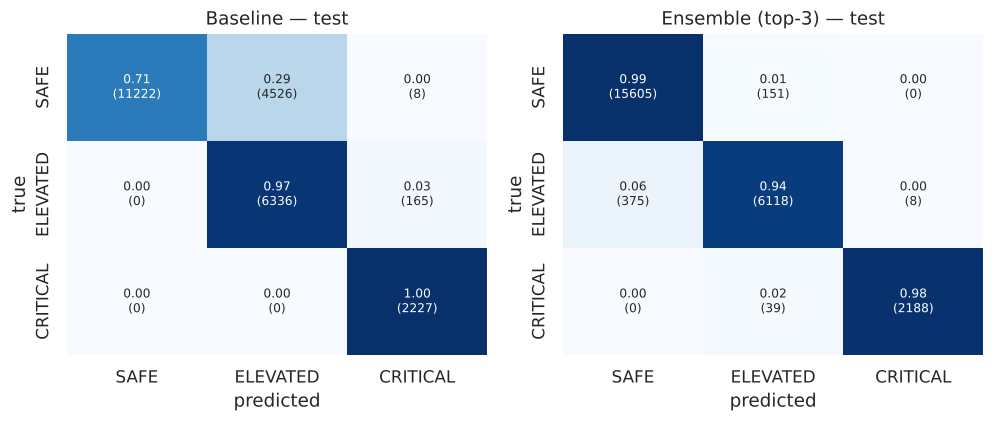

Classification report — Ensemble (top-3) (test)
              precision    recall  f1-score   support

        SAFE      0.977     0.990     0.983     15756
    ELEVATED      0.970     0.941     0.955      6501
    CRITICAL      0.996     0.982     0.989      2227

    accuracy                          0.977     24484
   macro avg      0.981     0.971     0.976     24484
weighted avg      0.977     0.977     0.976     24484



In [24]:
plot_cms({'Baseline': TEST_PRED['Baseline (max_risk_estimate)'], BEST: TEST_PRED[BEST]}, M_test, ' — test')
print(f'Classification report — {BEST} (test)')
print(classification_report(M_test.tier, tier_from(TEST_PRED[BEST], M_test.miss_distance), labels=TIERS, digits=3))

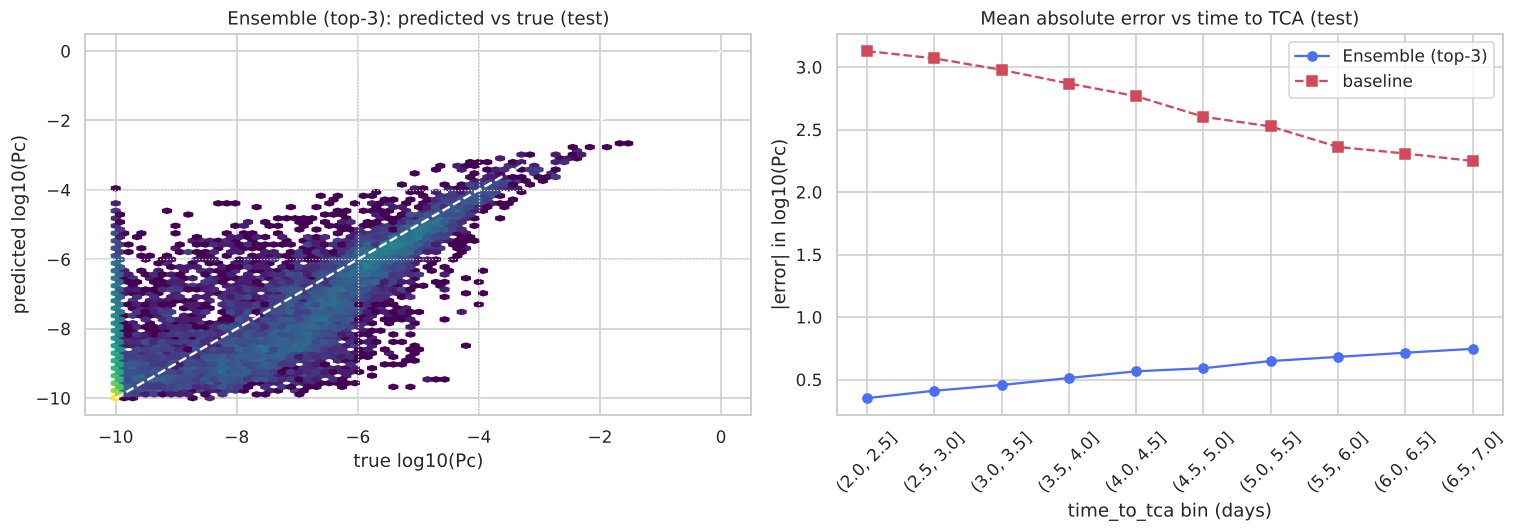

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
yp = np.clip(TEST_PRED[BEST], Y_FLOOR, 0)
ax[0].hexbin(M_test.y, yp, gridsize=60, bins='log', cmap='viridis'); ax[0].plot([Y_FLOOR, 0], [Y_FLOOR, 0], 'w--')
for v in (-6, -4): ax[0].axhline(v, c='w', ls=':', lw=.8); ax[0].axvline(v, c='w', ls=':', lw=.8)
ax[0].set(xlabel='true log10(Pc)', ylabel='predicted log10(Pc)', title=f'{BEST}: predicted vs true (test)')
# error vs time to TCA
err = pd.DataFrame({'tca': M_test.time_to_tca, 'err': np.abs(yp - M_test.y), 'base': np.abs(np.clip(M_test.max_risk_estimate, Y_FLOOR, 0) - M_test.y)})
err['bin'] = pd.cut(err.tca, np.arange(2, 7.5, .5))
e = err.groupby('bin', observed=True)[['err', 'base']].mean()
ax[1].plot(e.index.astype(str), e.err, 'o-', label=BEST, c='#4c6ef5'); ax[1].plot(e.index.astype(str), e.base, 's--', label='baseline', c='#d1495b')
ax[1].set(title='Mean absolute error vs time to TCA (test)', xlabel='time_to_tca bin (days)', ylabel='|error| in log10(Pc)'); ax[1].tick_params(axis='x', rotation=45); ax[1].legend()
plt.tight_layout(); plt.show()

### 9.1b Confusion matrix for every model (test)
Rows = true tier, columns = predicted tier. Each cell shows the row-normalised rate and the raw count.

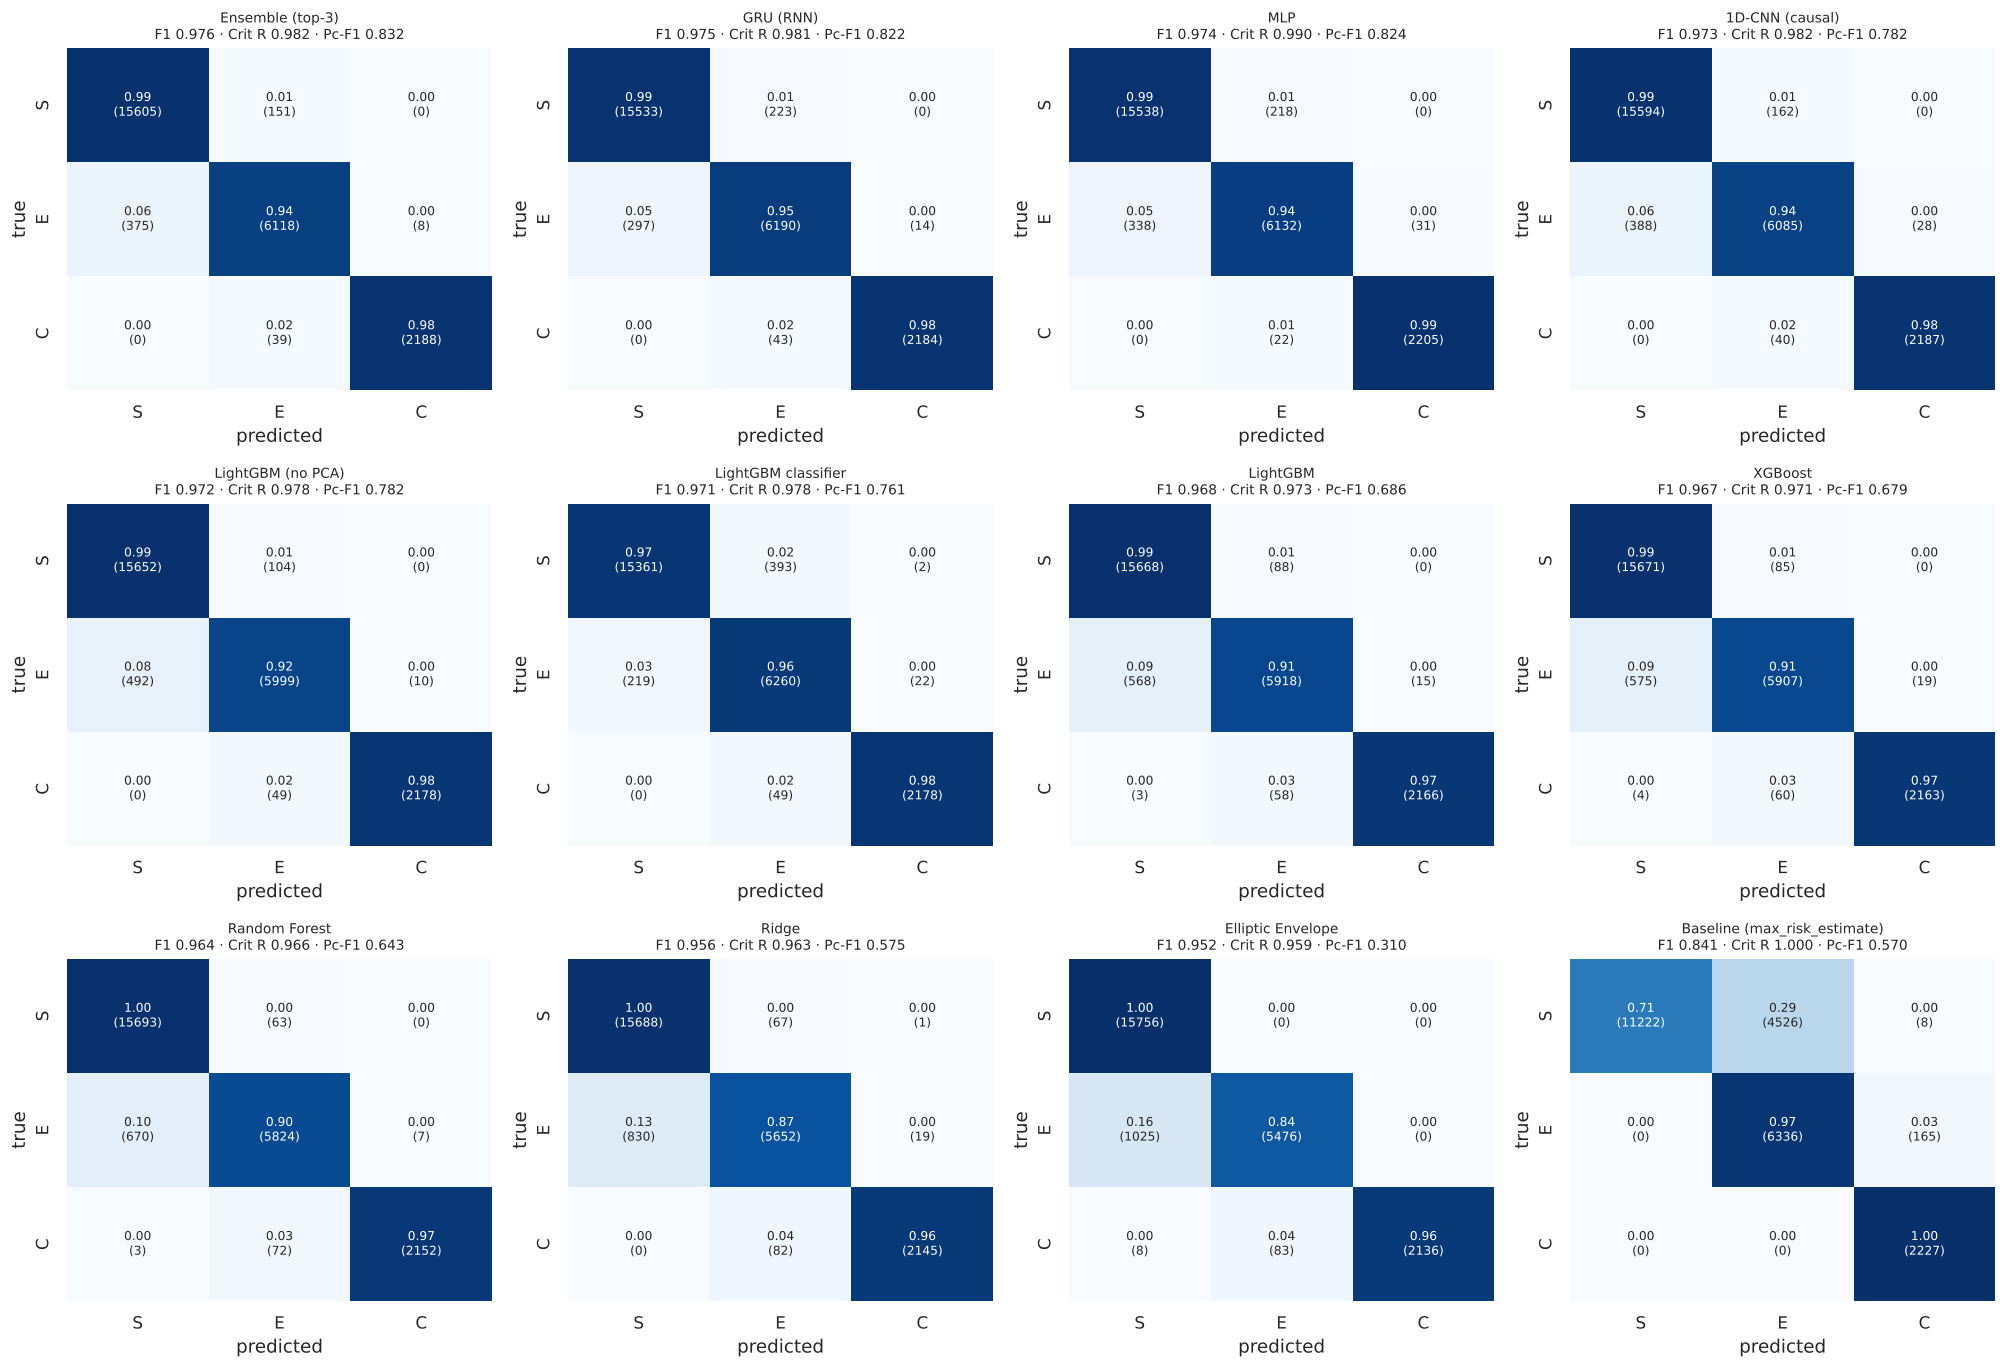

In [26]:
names = list(test_tbl.sort_values('macro_f1', ascending=False).index)
ncol = 4; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 4.2 * nrow))
for a, nm in zip(axes.flat, names):
    cm = confusion_matrix(M_test.tier, tier_from(TEST_PRED[nm], M_test.miss_distance), labels=TIERS)
    cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f'{cmn[i,j]:.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]), fmt='',
                cmap='Blues', vmin=0, vmax=1, xticklabels=['S', 'E', 'C'], yticklabels=['S', 'E', 'C'], cbar=False, ax=a, annot_kws={'size': 8})
    r = test_tbl.loc[nm]
    a.set_title(f'{nm}\nF1 {r.macro_f1:.3f} · Crit R {r.critical_recall:.3f} · Pc-F1 {r.pc_macro_f1:.3f}', fontsize=9)
    a.set_xlabel('predicted'); a.set_ylabel('true')
for a in list(axes.flat)[len(names):]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrices_test.png', dpi=130, bbox_inches='tight'); plt.show()
np.savez(f'{OUT_DIR}/test_predictions_all_models.npz', **{k: v for k, v in TEST_PRED.items()})

### 9.2 What drives the prediction? (PCA-space importance mapped back to features)

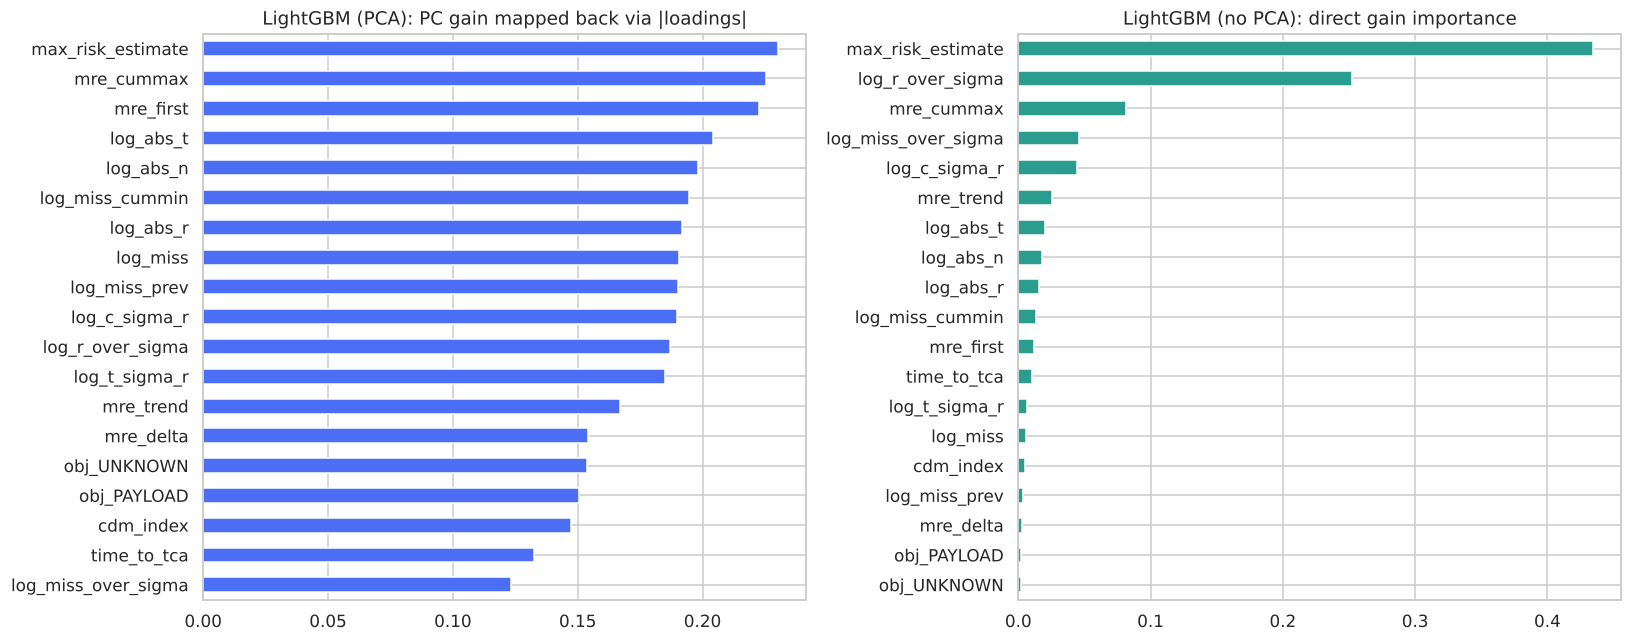

In [27]:
if BEST in classical or BEST.startswith('LightGBM') or BEST.startswith('Ensemble'):
    ref = classical['LightGBM']
    pc_imp = ref.booster_.feature_importance('gain'); pc_imp = pc_imp / pc_imp.sum()
    feat_imp = pd.Series(np.abs(pca.components_).T @ pc_imp, index=SELECTED).sort_values()
    raw_imp = pd.Series(lgb_raw.booster_.feature_importance('gain'), index=SELECTED); raw_imp = (raw_imp / raw_imp.sum()).sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    feat_imp.plot.barh(ax=ax[0], color='#4c6ef5'); ax[0].set_title('LightGBM (PCA): PC gain mapped back via |loadings|')
    raw_imp.plot.barh(ax=ax[1], color='#2a9d8f'); ax[1].set_title('LightGBM (no PCA): direct gain importance')
    plt.tight_layout(); plt.show()

### 9.3 Improvements 2 & 3: tuned cut-offs + selective safety net (tuned on validation only)
- **v1 hybrid:** ML tier with the brief's cut-offs, escalated to Critical whenever the CDM's own `max_risk_estimate ≥ −4` (the conservative upper bound never missed a Pc-critical CDM).
- **Improvement 2:** the regression under-predicts near the top, so the cut-offs applied to the **predicted** log10(Pc) are tuned (the truth always uses −4/−6).
- **Improvement 3:** escalate only when `max_risk_estimate ≥ −4` **and** the ML prediction ≥ a floor, cutting false alarms.

Cut-offs are grid-searched on **validation**. For the safety-net floor, validation is too small to bound the risk (every floor looks safe), so the floor uses a rule fixed in advance: **one decade below the lowest prediction any validation Pc-critical CDM received**. The aggressive val-optimal floor is kept as an ablation to show why. Test is evaluated once afterwards.

1296 configs tried, 1296 keep zero missed Critical on validation
Cut-offs on predicted log10(Pc): Critical ≥ -4.0, Elevated ≥ -6.25
Lowest prediction on a validation Pc-critical CDM: -4.69 → safety-net floor -6.0 (val-optimal aggressive floor would be -5.0)


,macro_f1,critical_recall,critical_precision,pc_critical_caught,critical_alerts
Baseline (max_risk_estimate),0.841,1.000,0.928,1.000,2400.000000
"Ensemble (top-3), brief cut-offs",0.976,0.982,0.996,0.833,2196.000000
"Ensemble (top-3), tuned cut-offs (impr. 2)",0.977,0.982,0.996,0.833,2196.000000
v1 hybrid (always escalate),0.964,1.000,0.928,1.000,2400.000000
FINAL: tuned + always-on net,0.965,1.000,0.928,1.000,2400.000000
"impr. 3: selective net, margin floor -6.0",0.972,0.999,0.957,0.991,2325.000000
"impr. 3: selective net, aggressive floor -5.0",0.975,0.999,0.969,0.991,2296.000000


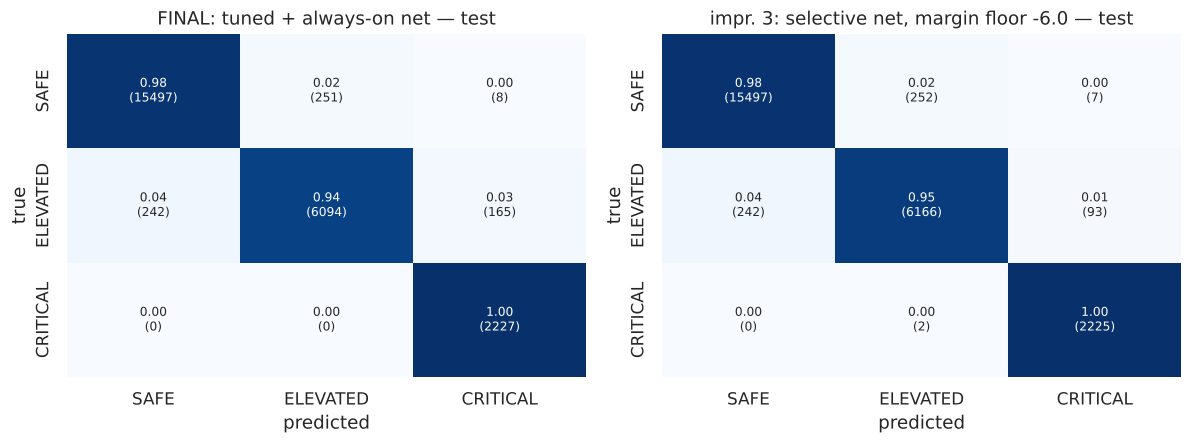

In [28]:
ENC = {'SAFE': 0, 'ELEVATED': 1, 'CRITICAL': 2}
enc = lambda t: np.vectorize(ENC.get)(np.asarray(t))

def fast_metrics(true_i, pred_i, pc_true_i):
    cm = np.bincount(true_i * 3 + pred_i, minlength=9).reshape(3, 3)
    tp_ = np.diag(cm); prec = tp_ / np.maximum(cm.sum(0), 1); rec = tp_ / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    pc_mask = pc_true_i == 2
    return {'macro_f1': f1.mean(), 'critical_recall': rec[2], 'critical_precision': prec[2],
            'pc_critical_caught': (pred_i[pc_mask] == 2).mean(), 'critical_alerts': int((pred_i == 2).sum())}

def run_cfg(pred, meta, crit, elev, floor, net=True):
    if net:
        return hybrid_tier(pred, meta.miss_distance.values, meta.max_risk_estimate.values, crit, elev, floor)
    return tier_from(pred, meta.miss_distance.values, crit, elev)

true_va, pcv = enc(M_va.tier), enc(pc_tier(M_va.y.values))
grid = []
for crit in np.round(np.arange(-5.0, -3.45, 0.1), 2):
    for elev in np.round(np.arange(-7.5, -5.49, 0.25), 2):
        for floor in [None, -9.0, -8.0, -7.5, -7.0, -6.5, -6.0, -5.5, -5.0]:
            r = fast_metrics(true_va, enc(run_cfg(VAL_PRED[BEST], M_va, crit, elev, floor)), pcv)
            grid.append({'crit_cut': crit, 'elev_cut': elev, 'net_floor': floor, **r})
G = pd.DataFrame(grid)
safe_cfgs = G[(G.critical_recall >= 1.0) & (G.pc_critical_caught >= 1.0)]
print(f'{len(G)} configs tried, {len(safe_cfgs)} keep zero missed Critical on validation')
# Cut-offs: best validation macro-F1 with the always-on safety net
cfg = G[G.net_floor.isna()].sort_values(['macro_f1', 'critical_precision'], ascending=False).iloc[0]
CRIT_CUT, ELEV_CUT = float(cfg.crit_cut), float(cfg.elev_cut)
# Safety-net floor: validation alone can't bound this (every floor in the grid looks safe on ~120 Pc-critical CDMs),
# so the val-optimal floor sits at the grid edge. Rule fixed in advance instead: one decade below the lowest
# prediction any validation Pc-critical CDM received.
AGGR_FLOOR = float(safe_cfgs.sort_values(['macro_f1', 'critical_precision'], ascending=False).iloc[0].net_floor)
min_pred_crit = VAL_PRED[BEST][M_va.pc_tier.values == 'CRITICAL'].min()
NET_FLOOR = float(np.floor((min_pred_crit - 1.0) * 2) / 2)
print(f'Cut-offs on predicted log10(Pc): Critical ≥ {CRIT_CUT}, Elevated ≥ {ELEV_CUT}')
print(f'Lowest prediction on a validation Pc-critical CDM: {min_pred_crit:.2f} → safety-net floor {NET_FLOOR} '
      f'(val-optimal aggressive floor would be {AGGR_FLOOR})')

# Test: evaluated once
true_te, pct = enc(M_test.tier), enc(pc_tier(M_test.y.values))
pb = TEST_PRED[BEST]
variants = {
    'Baseline (max_risk_estimate)': tier_from(M_test.max_risk_estimate, M_test.miss_distance),
    f'{BEST}, brief cut-offs': run_cfg(pb, M_test, -4, -6, None, net=False),
    f'{BEST}, tuned cut-offs (impr. 2)': run_cfg(pb, M_test, CRIT_CUT, ELEV_CUT, None, net=False),
    'v1 hybrid (always escalate)': run_cfg(pb, M_test, -4, -6, None),
    'FINAL: tuned + always-on net': run_cfg(pb, M_test, CRIT_CUT, ELEV_CUT, None),
    f'impr. 3: selective net, margin floor {NET_FLOOR}': run_cfg(pb, M_test, CRIT_CUT, ELEV_CUT, NET_FLOOR),
    f'impr. 3: selective net, aggressive floor {AGGR_FLOOR}': run_cfg(pb, M_test, CRIT_CUT, ELEV_CUT, AGGR_FLOOR),
}
hyb = pd.DataFrame({k: fast_metrics(true_te, enc(v), pct) for k, v in variants.items()}).T
FINAL_TEST = variants['FINAL: tuned + always-on net']
hyb.to_csv(f'{OUT_DIR}/final_comparison_test.csv')
display(hyb.style.format({c: '{:.3f}' for c in hyb.columns if c != 'critical_alerts'})
        .background_gradient(cmap='Greens', subset=['macro_f1', 'critical_precision']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, nm in zip(ax, ['FINAL: tuned + always-on net', f'impr. 3: selective net, margin floor {NET_FLOOR}']):
    cm = confusion_matrix(M_test.tier, variants[nm], labels=TIERS)
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=np.array([[f'{cm[i,j]/cm[i].sum():.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]),
                fmt='', cmap='Blues', xticklabels=TIERS, yticklabels=TIERS, cbar=False, annot_kws={'size': 8}, ax=a)
    a.set(title=f'{nm} — test', xlabel='predicted', ylabel='true')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/final_confusion_test.png', dpi=130, bbox_inches='tight'); plt.show()

**Decision.** Zero missed Critical CDMs is a hard safety requirement, and validation cannot prove a selective net meets it (every floor in the grid looked safe on validation). So the **final system keeps the always-on safety net** with the tuned cut-offs. The selective net (improvement 3) is reported as an explored trade-off: a few percent fewer Critical alerts, at the cost of rare missed Critical CDMs.

## 10. Warnings & operational insights
### 10.1 24-hour warnings (full training data — the test set has no CDMs inside 2 days)
For every event, take the latest CDM received within 24 h of TCA and count how many breach the dangerous thresholds.

Events with a CDM inside 24 h of TCA: 9,463 of 13,154
  ↳ miss < 1 km (CRITICAL):     621
  ↳ miss ≤ 5 km (ELEVATED+):    2,440
  ↳ Pc ≥ 1e-4 (manoeuvre):      8
  ↳ final tier counts: {'SAFE': 6999, 'ELEVATED': 1841, 'CRITICAL': 623}


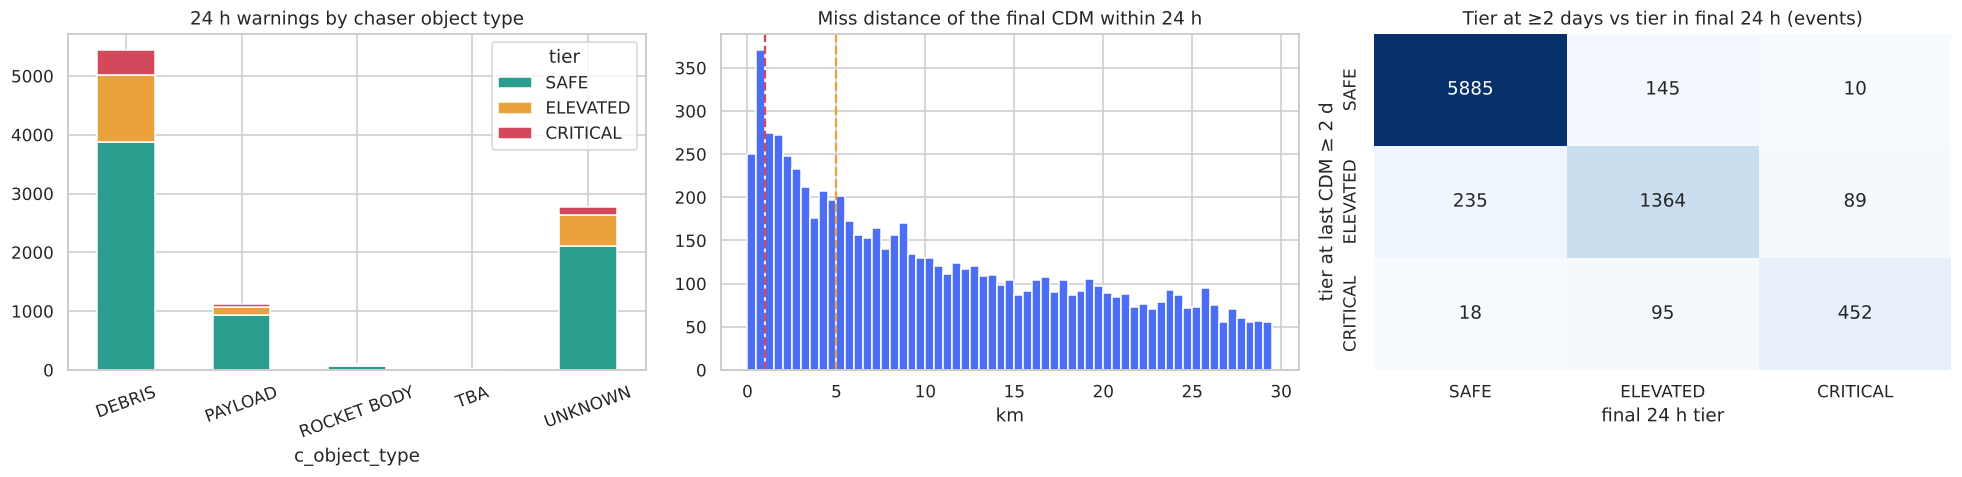

In [29]:
w24 = train_full[train_full.time_to_tca <= 1].sort_values('time_to_tca').groupby('event_id').head(1)   # latest CDM within 24 h
w24 = w24.assign(within_1km=w24.miss_distance < 1000, within_5km=w24.miss_distance <= 5000, pc_crit=w24[LABEL] >= -4)
n_ev = train_full.event_id.nunique()
print(f'Events with a CDM inside 24 h of TCA: {len(w24):,} of {n_ev:,}')
print(f'  ↳ miss < 1 km (CRITICAL):     {w24.within_1km.sum():,}')
print(f'  ↳ miss ≤ 5 km (ELEVATED+):    {w24.within_5km.sum():,}')
print(f'  ↳ Pc ≥ 1e-4 (manoeuvre):      {w24.pc_crit.sum():,}')
print(f'  ↳ final tier counts:', w24.tier.value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
pd.crosstab(w24.c_object_type, w24.tier)[TIERS].plot.bar(stacked=True, ax=ax[0], color=[TIER_COLORS[t] for t in TIERS], rot=20)
ax[0].set_title('24 h warnings by chaser object type')
ax[1].hist(w24.miss_distance / 1e3, bins=np.arange(0, 30, .5), color='#4c6ef5'); ax[1].axvline(1, c=TIER_COLORS['CRITICAL'], ls='--'); ax[1].axvline(5, c=TIER_COLORS['ELEVATED'], ls='--')
ax[1].set(title='Miss distance of the final CDM within 24 h', xlabel='km')
early = train_full[train_full.time_to_tca >= 2].sort_values('time_to_tca').groupby('event_id').head(1)[['event_id', 'tier']]
trans = early.merge(w24[['event_id', 'tier']], on='event_id', suffixes=('_2d', '_final'))
sns.heatmap(pd.crosstab(trans.tier_2d, trans.tier_final).reindex(index=TIERS, columns=TIERS), annot=True, fmt='d', cmap='Blues', ax=ax[2], cbar=False)
ax[2].set(title='Tier at ≥2 days vs tier in final 24 h (events)', xlabel='final 24 h tier', ylabel='tier at last CDM ≥ 2 d')
plt.tight_layout(); plt.show()
w24[['event_id', 'time_to_tca', 'c_object_type', 'miss_distance', LABEL, 'tier']].to_csv(f'{OUT_DIR}/warnings_24h_train.csv', index=False)
trans.to_csv(f'{OUT_DIR}/tier_transition_train.csv', index=False)

### 10.2 Early-warning view on the test set (per event)
For each test event: the latest CDM's final tier, and the **lead time** — how many days before TCA the system first flagged it Critical.

Event-level tier (latest CDM) — test
              precision    recall  f1-score   support

        SAFE      0.989     0.992     0.991      1481
    ELEVATED      0.975     0.948     0.961       500
    CRITICAL      0.949     1.000     0.974       186

    accuracy                          0.982      2167
   macro avg      0.971     0.980     0.975      2167
weighted avg      0.983     0.982     0.982      2167

Events flagged Critical at some point: 393 / 2167; median lead time 6.09 days before TCA


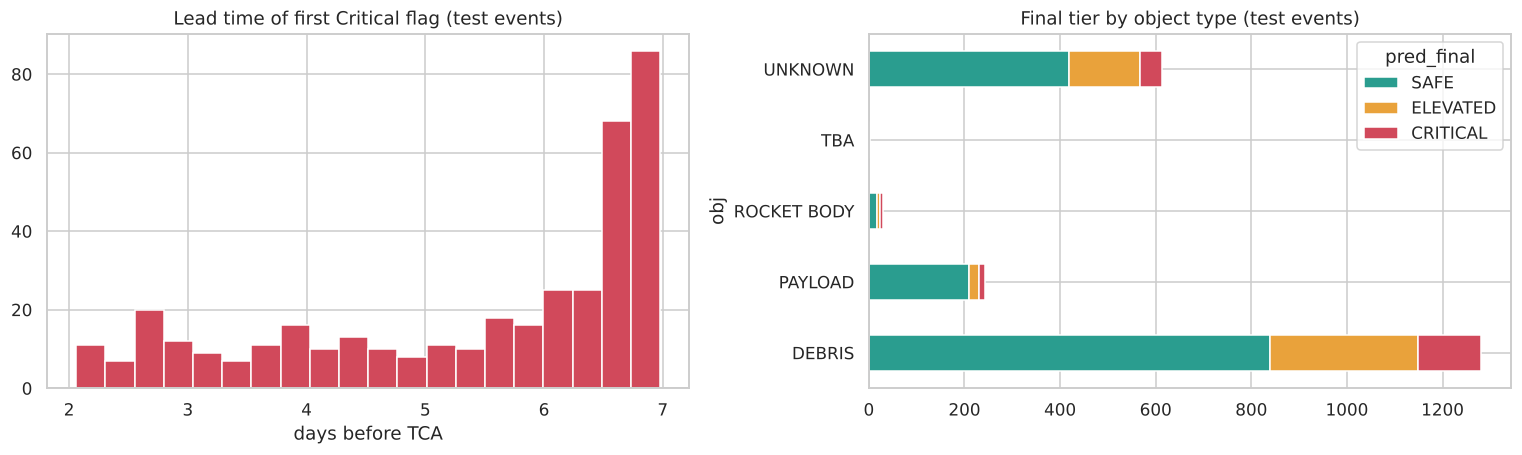

In [30]:
tp = M_test.assign(pred_risk=TEST_PRED[BEST], pred_tier=tier_from(TEST_PRED[BEST], M_test.miss_distance, CRIT_CUT, ELEV_CUT),
                   final_tier=FINAL_TEST, base_tier=tier_from(M_test.max_risk_estimate, M_test.miss_distance))
ev = tp.groupby('event_id').agg(true_final=('tier', 'last'), pred_final=('final_tier', 'last'), obj=('c_object_type', 'first'),
                                 last_tca=('time_to_tca', 'last'), min_miss_km=('miss_distance', lambda s: s.min() / 1e3))
first_flag = tp[tp.final_tier == 'CRITICAL'].groupby('event_id').time_to_tca.max().rename('first_critical_flag_days')
ev = ev.join(first_flag)
print('Event-level tier (latest CDM) — test')
print(classification_report(ev.true_final, ev.pred_final, labels=TIERS, digits=3))
print(f'Events flagged Critical at some point: {ev.first_critical_flag_days.notna().sum()} / {len(ev)}; '
      f'median lead time {ev.first_critical_flag_days.median():.2f} days before TCA')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].hist(ev.first_critical_flag_days.dropna(), bins=20, color=TIER_COLORS['CRITICAL']); ax[0].set(title='Lead time of first Critical flag (test events)', xlabel='days before TCA')
pd.crosstab(ev.obj, ev.pred_final)[TIERS].plot.barh(stacked=True, ax=ax[1], color=[TIER_COLORS[t] for t in TIERS]); ax[1].set_title('Final tier by object type (test events)')
plt.tight_layout(); plt.show()

### 10.3 Human-review flag
CDMs whose predicted log10(Pc) sits within ±0.5 of a (tuned) decision cut-off are flagged for an analyst. This is where the model is least certain.

In [31]:
tp['review_flag'] = (np.abs(tp.pred_risk - ELEV_CUT) < .5) | (np.abs(tp.pred_risk - CRIT_CUT) < .5)
tp['pc_error'] = pc_tier(tp.pred_risk, CRIT_CUT, ELEV_CUT) != tp.pc_tier
print(f'Review-flagged CDMs: {tp.review_flag.mean():.1%} of test rows')
print(f'Pc-tier error rate — flagged: {tp[tp.review_flag].pc_error.mean():.1%} · not flagged: {tp[~tp.review_flag].pc_error.mean():.1%}')
print(f'Share of all Pc-tier errors caught by the flag: {tp[tp.pc_error].review_flag.mean():.1%}')

Review-flagged CDMs: 9.5% of test rows
Pc-tier error rate — flagged: 32.3% · not flagged: 2.1%
Share of all Pc-tier errors caught by the flag: 61.5%


### 10.4 Human in the loop vs autonomous manoeuvre — how much time does a human have?
**Reaction budget** = time to TCA − time needed to uplink and execute the burn (`EXEC_LEAD_DAYS`, assumed 0.5 d).
Action levels (thresholds are assumptions in `risk_utils.py`, easy to change):

| Level | When | Who acts |
|---|---|---|
| **AUTONOMOUS** | Critical, budget ≤ 0, model confident | System executes the pre-planned manoeuvre; operator can veto |
| **URGENT** | Critical, budget < 1 day (or no time but model uncertain) | Human decides now; plan prepared and armed |
| **PLAN** | Critical, budget ≥ 1 day | Analyst plans; waits for more CDMs if useful |
| **REVIEW** | Elevated and near a threshold | Analyst checks |
| **MONITOR** | Elevated | Re-assess on next CDM |
| **NO ACTION** | Safe | — |

**Ground truth timing (full train data):** for every event that ever becomes Critical, when did it first become Critical? That decides whether a human would have had time.

1,808 train events become Critical at some point. First became Critical:
  < 0.5 d → AUTONOMOUS                30  (1.7%)
  0.5–1.5 d → URGENT                  91  (5.0%)
  1.5–2 d → PLAN (tight)              70  (3.9%)
  ≥ 2 d → PLAN                      1617  (89.4%)
Median human reaction budget at first Critical: 4.92 days
Late escalations (< 1.5 d): 121; their tier at ≥ 2 d before TCA: {'ELEVATED': 36, 'SAFE': 17}


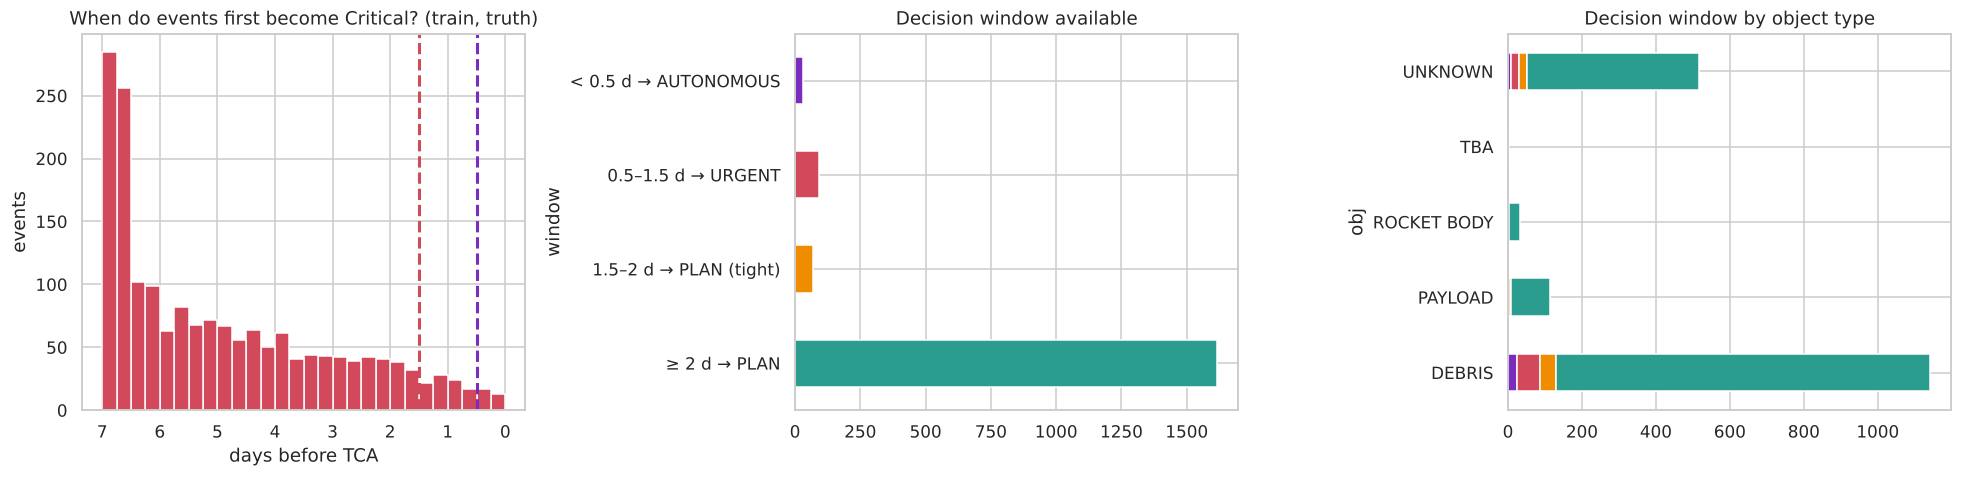

In [32]:
first_crit = (train_full[train_full.tier == 'CRITICAL'].groupby('event_id')
              .agg(first_crit_tca=('time_to_tca', 'max'), obj=('c_object_type', 'first'),
                   by_pc=(LABEL, lambda s: (s >= -4).any())))
bins = [-1, EXEC_LEAD_DAYS, EXEC_LEAD_DAYS + HUMAN_MIN_DAYS, 2, 99]
labels = [f'< {EXEC_LEAD_DAYS} d → AUTONOMOUS', f'{EXEC_LEAD_DAYS}–{EXEC_LEAD_DAYS + HUMAN_MIN_DAYS} d → URGENT',
          f'{EXEC_LEAD_DAYS + HUMAN_MIN_DAYS}–2 d → PLAN (tight)', '≥ 2 d → PLAN']
first_crit['window'] = pd.cut(first_crit.first_crit_tca, bins, labels=labels)
first_crit['reaction_budget_days'] = reaction_budget_days(first_crit.first_crit_tca)
win = first_crit.window.value_counts().reindex(labels)
print(f'{len(first_crit):,} train events become Critical at some point. First became Critical:')
for k, v in win.items(): print(f'  {k:32s} {v:5d}  ({v / len(first_crit):.1%})')
print(f'Median human reaction budget at first Critical: {first_crit.reaction_budget_days.median():.2f} days')
late = first_crit[first_crit.first_crit_tca < EXEC_LEAD_DAYS + HUMAN_MIN_DAYS]
prior = train_full[train_full.event_id.isin(late.index) & (train_full.time_to_tca >= 2)].sort_values('time_to_tca').groupby('event_id').tier.first()
print(f'Late escalations (< {EXEC_LEAD_DAYS + HUMAN_MIN_DAYS} d): {len(late)}; their tier at ≥ 2 d before TCA: {prior.value_counts().to_dict()}')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].hist(first_crit.first_crit_tca, bins=np.arange(0, 7.25, .25), color=TIER_COLORS['CRITICAL'])
for x, c in [(EXEC_LEAD_DAYS, ACTION_COLORS['AUTONOMOUS']), (EXEC_LEAD_DAYS + HUMAN_MIN_DAYS, ACTION_COLORS['URGENT'])]: ax[0].axvline(x, c=c, ls='--', lw=2)
ax[0].invert_xaxis(); ax[0].set(title='When do events first become Critical? (train, truth)', xlabel='days before TCA', ylabel='events')
win.plot.barh(ax=ax[1], color=[ACTION_COLORS['AUTONOMOUS'], ACTION_COLORS['URGENT'], ACTION_COLORS['PLAN'], '#2a9d8f'])
ax[1].set_title('Decision window available'); ax[1].invert_yaxis()
pd.crosstab(first_crit.obj, first_crit.window)[labels].plot.barh(stacked=True, ax=ax[2], legend=False,
            color=[ACTION_COLORS['AUTONOMOUS'], ACTION_COLORS['URGENT'], ACTION_COLORS['PLAN'], '#2a9d8f'])
ax[2].set_title('Decision window by object type')
plt.tight_layout(); plt.show()
first_crit.to_csv(f'{OUT_DIR}/escalation_timing_train.csv')

**Action levels on the test predictions.** All test CDMs are ≥ 2 days out, so every Critical event leaves a human ≥ 1.5 days — the system's job here is to prioritise the analyst queue, not to act autonomously.

In [33]:
tp['reaction_budget_days'] = reaction_budget_days(tp.time_to_tca)
tp['action'] = action_level(tp.final_tier, tp.time_to_tca, tp.review_flag, tp.miss_distance)
ev_latest = tp.groupby('event_id').tail(1).set_index('event_id')
ev['action'] = ev_latest.action
ev['reaction_budget_at_first_flag_days'] = ev.first_critical_flag_days - EXEC_LEAD_DAYS
print('Action level of the latest CDM per test event:'); print(ev.action.value_counts().reindex(ACTIONS).fillna(0).astype(int))
print(f'Reaction budget at first Critical flag — median {ev.reaction_budget_at_first_flag_days.median():.2f} d, '
      f'min {ev.reaction_budget_at_first_flag_days.min():.2f} d')

Action level of the latest CDM per test event:
action
AUTONOMOUS       0
URGENT           0
PLAN           196
REVIEW          56
MONITOR        430
NO ACTION     1485
Name: count, dtype: int64
Reaction budget at first Critical flag — median 5.59 d, min 1.56 d


### 10.5 The cost of waiting: delta-v vs decision time
An along-track burn Δv grows the along-track separation by about **3·Δv·t** by TCA (Clohessy–Wiltshire secular drift, valid when t ≫ one orbit ≈ 1.5 h).
So the Δv needed for a given extra separation scales as **1 / lead time**: deciding late costs propellant (and leaves less margin for error).

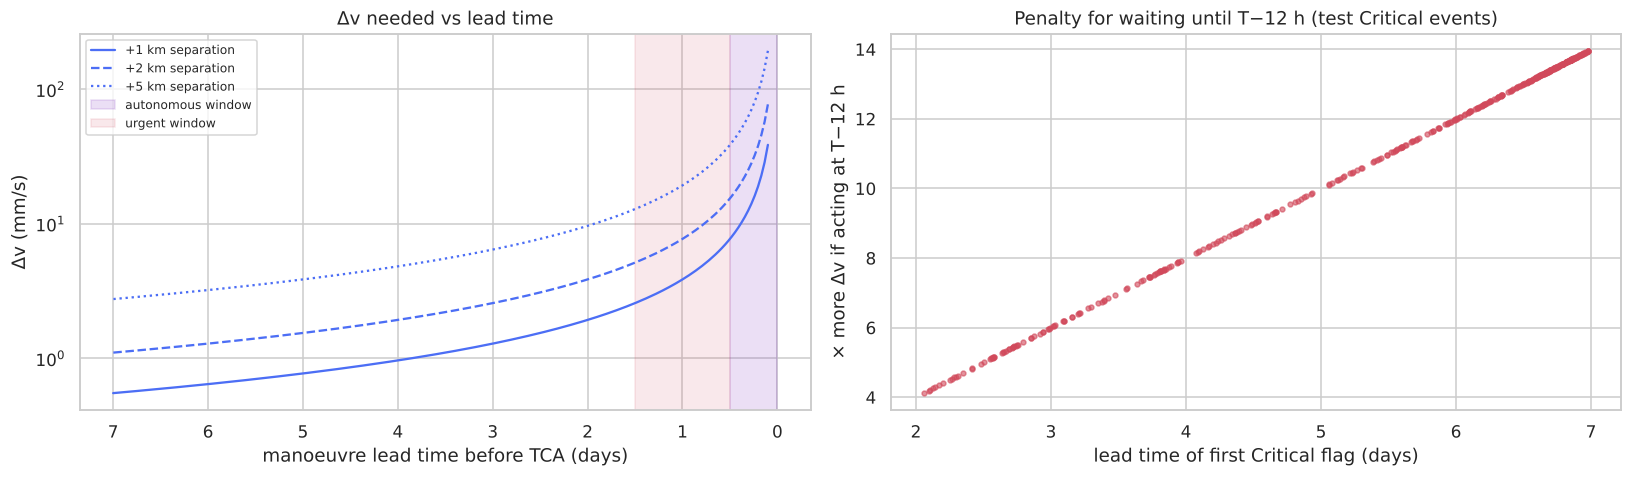

Test Critical events: median Δv to reach 5 km if acting at first flag = 2.50 mm/s; at T−12 h = 29.82 mm/s (12.2× more)


In [34]:
lead = np.linspace(0.1, 7, 200)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for sep, ls in [(1000, '-'), (2000, '--'), (5000, ':')]:
    ax[0].plot(lead, dv_required_mm_s(sep, lead), ls, c='#4c6ef5', label=f'+{sep/1e3:.0f} km separation')
ax[0].axvspan(0, EXEC_LEAD_DAYS, color=ACTION_COLORS['AUTONOMOUS'], alpha=.15, label='autonomous window')
ax[0].axvspan(EXEC_LEAD_DAYS, EXEC_LEAD_DAYS + HUMAN_MIN_DAYS, color=ACTION_COLORS['URGENT'], alpha=.12, label='urgent window')
ax[0].set(yscale='log', xlabel='manoeuvre lead time before TCA (days)', ylabel='Δv (mm/s)', title='Δv needed vs lead time'); ax[0].invert_xaxis(); ax[0].legend(fontsize=8)

crit_ev = ev[ev.first_critical_flag_days.notna()].join(tp.groupby('event_id').miss_distance.last().rename('miss_last'))
need = np.clip(5000 - crit_ev.miss_last, 500, None)                     # separation to reach the 5 km "safe" radius
crit_ev['dv_at_first_flag'] = dv_required_mm_s(need, crit_ev.first_critical_flag_days)
crit_ev['dv_at_12h'] = dv_required_mm_s(need, 0.5)
ax[1].scatter(crit_ev.first_critical_flag_days, crit_ev.dv_at_12h / crit_ev.dv_at_first_flag, s=10, c=TIER_COLORS['CRITICAL'], alpha=.6)
ax[1].set(xlabel='lead time of first Critical flag (days)', ylabel='× more Δv if acting at T−12 h', title='Penalty for waiting until T−12 h (test Critical events)')
plt.tight_layout(); plt.show()
print(f'Test Critical events: median Δv to reach 5 km if acting at first flag = {crit_ev.dv_at_first_flag.median():.2f} mm/s; '
      f'at T−12 h = {crit_ev.dv_at_12h.median():.2f} mm/s ({(crit_ev.dv_at_12h / crit_ev.dv_at_first_flag).median():.1f}× more)')

### 10.6 Monte Carlo: what-if manoeuvre simulation
**Why not use Monte Carlo as the Pc estimator?** A proper Pc needs both objects' full position covariances and the hard-body radius; the brief only allows the radial sigmas.
So MC here is a **what-if tool**, not the classifier: sample the relative position at TCA from a Gaussian around the CDM's miss vector
(σ_R = combined radial sigma, σ_T = f_T·σ_R, σ_N = f_N·σ_R), count samples inside the hard-body sphere,
then shift the mean along-track by a manoeuvre and see how Pc falls.

The unknown f_T, f_N and hard-body radius are **calibrated on training data** against the dataset's Pc (fast analytic version of the same model), then the MC is checked on test.

Calibration on train (best 5 by RMSE of log10 Pc):


,f_T,f_N,hbr_m,rmse,spearman
59,100,80,50,1.585,0.447
74,150,80,50,1.593,0.437
56,100,50,50,1.597,0.466
71,150,50,50,1.600,0.460
44,60,80,50,1.631,0.446


MC parameters: {'t_factor': 100.0, 'n_factor': 80.0, 'hbr': 50.0}


328 events in 6.0s · Spearman(MC log Pc, dataset log Pc) = 0.330 · Spearman(model prediction, dataset) = 0.930


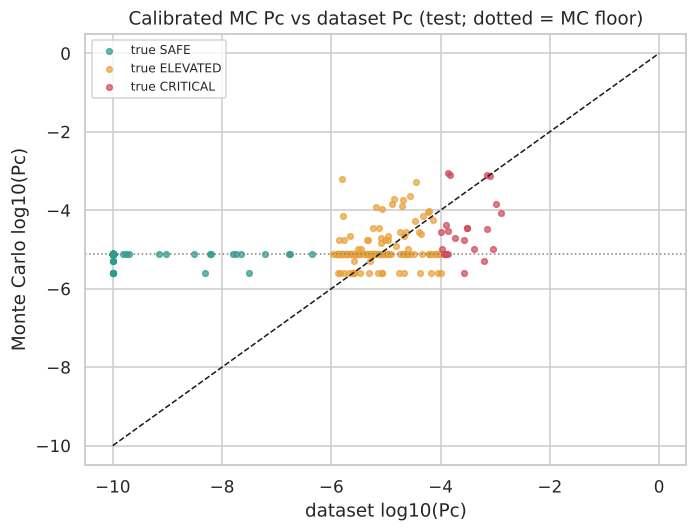

In [35]:
from scipy.stats import spearmanr
import itertools
from risk_utils import pc_analytic_log10
cal = train_raw[train_raw[LABEL] > -10].sample(30000, random_state=SEED)
cal_rows = []
for ft, fn, h in itertools.product([5, 20, 60, 100, 150], [1, 5, 20, 50, 80], [10, 20, 50]):
    lp = np.clip(pc_analytic_log10(cal[['relative_position_r', 'relative_position_t', 'relative_position_n']].values,
                                   cal.t_sigma_r.values, cal.c_sigma_r.values, h, ft, fn), -10, 0)
    cal_rows.append({'f_T': ft, 'f_N': fn, 'hbr_m': h, 'rmse': np.sqrt(np.mean((lp - cal[LABEL].values) ** 2)),
                     'spearman': spearmanr(lp, cal[LABEL].values).correlation})
CAL = pd.DataFrame(cal_rows).sort_values('rmse')
MC_PARAMS = dict(t_factor=float(CAL.iloc[0].f_T), n_factor=float(CAL.iloc[0].f_N), hbr=float(CAL.iloc[0].hbr_m))
print('Calibration on train (best 5 by RMSE of log10 Pc):'); display(CAL.head(5).round(3))
print('MC parameters:', MC_PARAMS)
rs = np.random.RandomState(SEED)
last_cdm = tp.groupby('event_id').tail(1)
chk = pd.concat([last_cdm[last_cdm.pc_tier != 'SAFE'], last_cdm[last_cdm.pc_tier == 'SAFE'].sample(150, random_state=SEED)])
t0 = time.time()
mc = [mc_pc([r.relative_position_r, r.relative_position_t, r.relative_position_n], r.t_sigma_r, r.c_sigma_r, n=400_000, seed=i, **MC_PARAMS)
      for i, r in enumerate(chk.itertuples())]
chk = chk.assign(mc_log_pc=np.log10([m[0] for m in mc]), mc_bound=[m[1] for m in mc])
rho = spearmanr(chk.mc_log_pc, chk.y).correlation
print(f'{len(chk)} events in {time.time()-t0:.1f}s · Spearman(MC log Pc, dataset log Pc) = {rho:.3f} · '
      f'Spearman(model prediction, dataset) = {spearmanr(chk.pred_risk, chk.y).correlation:.3f}')
fig, ax = plt.subplots(figsize=(6.5, 5))
for t in TIERS:
    q = chk[chk.pc_tier == t]; ax.scatter(q.y, q.mc_log_pc, s=14, c=TIER_COLORS[t], label=f'true {t}', alpha=.7)
ax.plot([-10, 0], [-10, 0], 'k--', lw=1); ax.axhline(np.log10(3 / 400_000), c='grey', ls=':', lw=1)
ax.set(xlabel='dataset log10(Pc)', ylabel='Monte Carlo log10(Pc)', title='Calibrated MC Pc vs dataset Pc (test; dotted = MC floor)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What-if:** the most dangerous test event (highest predicted Pc among Critical events). Pc after an along-track burn of Δv, executed at different lead times.

Event 1259: miss 44 m, dataset log10(Pc) -1.53, model -2.66, MC (no manoeuvre) -3.06


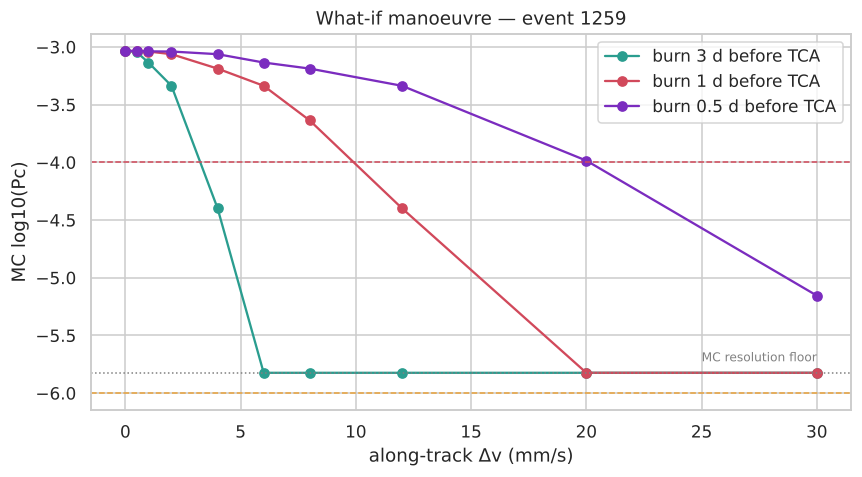

,lead_days,dv_for_pc_below_1e-5_mm_s
0,3.0,6.0
1,1.0,20.0
2,0.5,30.0


In [36]:
cand = tp[tp.final_tier == 'CRITICAL'].sort_values('pred_risk', ascending=False)
row = cand.iloc[0]
rel = [row.relative_position_r, row.relative_position_t, row.relative_position_n]
pc0, _ = mc_pc(rel, row.t_sigma_r, row.c_sigma_r, n=1_000_000, **MC_PARAMS)
print(f'Event {row.event_id}: miss {row.miss_distance:.0f} m, dataset log10(Pc) {row[LABEL]:.2f}, model {row.pred_risk:.2f}, '
      f'MC (no manoeuvre) {np.log10(pc0):.2f}')
dvs = np.array([0, 0.5, 1, 2, 4, 6, 8, 12, 20, 30])
fig, ax = plt.subplots(figsize=(8, 4.5))
whatif = []
for ld, c in [(3, '#2a9d8f'), (1, ACTION_COLORS['URGENT']), (0.5, ACTION_COLORS['AUTONOMOUS'])]:
    pcs = [mc_pc(rel, row.t_sigma_r, row.c_sigma_r, shift_t_m=along_track_shift_m(dv, ld), n=2_000_000, seed=1, **MC_PARAMS)[0] for dv in dvs]
    ax.plot(dvs, np.log10(pcs), 'o-', c=c, label=f'burn {ld} d before TCA')
    below = dvs[np.array(pcs) < 1e-5]
    whatif.append({'lead_days': ld, 'dv_for_pc_below_1e-5_mm_s': below.min() if len(below) else np.nan})
ax.axhline(-4, c=TIER_COLORS['CRITICAL'], ls='--', lw=1); ax.axhline(-6, c=TIER_COLORS['ELEVATED'], ls='--', lw=1)
ax.axhline(np.log10(3 / 2_000_000), c='grey', ls=':', lw=1); ax.text(dvs[-1], np.log10(3 / 2_000_000) + .1, 'MC resolution floor', ha='right', fontsize=8, color='grey')
ax.set(xlabel='along-track Δv (mm/s)', ylabel='MC log10(Pc)', title=f'What-if manoeuvre — event {row.event_id}'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(whatif))

## 11. Failure cases (honest evaluation)
1. **What the ML alone misses:** truth is Critical because of Pc, but the model predicts lower — these are what the safety net is for.
2. **What the final system still gets wrong:** remaining confusions after the safety net.

Pc-critical CDMs in test: 233 · missed by Ensemble (top-3) alone: 39 · rescued by safety net: 100%
Remaining errors of the final system (true → predicted):


,tier,final_tier,count
0,ELEVATED,CRITICAL,165
1,ELEVATED,SAFE,242
2,SAFE,CRITICAL,8
3,SAFE,ELEVATED,251


,event_id,time_to_tca,miss_distance,c_object_type,max_risk_estimate,risk,pred_risk,final_tier
22454,1984,2.718,3078.0,PAYLOAD,-3.640,-3.640,-4.464,CRITICAL
4982,441,3.180,1196.0,DEBRIS,-3.646,-3.646,-4.021,CRITICAL
4983,441,2.919,1366.0,DEBRIS,-3.666,-3.691,-4.151,CRITICAL
6295,560,2.966,3849.0,DEBRIS,-3.728,-3.726,-4.077,CRITICAL
6297,560,2.256,3858.0,DEBRIS,-3.730,-3.728,-4.166,CRITICAL
5009,443,4.420,1299.0,DEBRIS,-3.596,-3.745,-4.092,CRITICAL
6296,560,2.555,3948.0,DEBRIS,-3.753,-3.753,-4.174,CRITICAL
19385,1714,4.384,2244.0,UNKNOWN,-3.749,-3.754,-4.053,CRITICAL


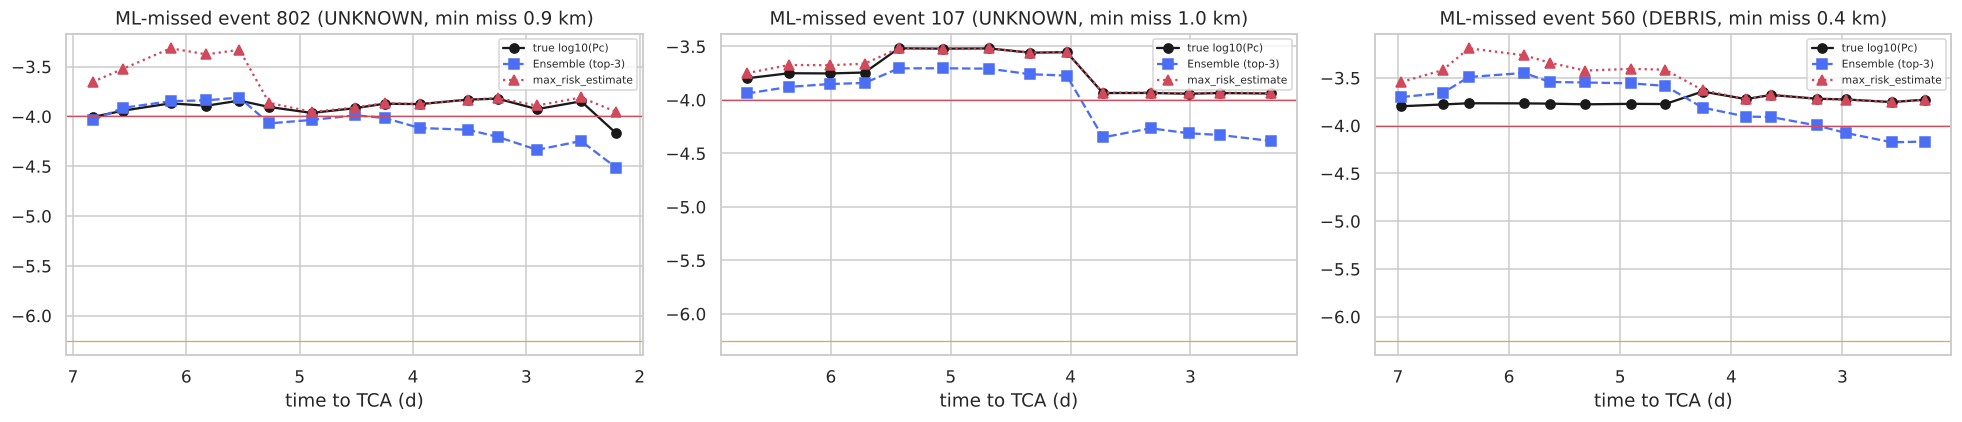

In [37]:
fn = tp[(tp.pc_tier == 'CRITICAL') & (tp.pred_tier != 'CRITICAL')]
rescued = (fn.final_tier == 'CRITICAL').mean() if len(fn) else np.nan
print(f'Pc-critical CDMs in test: {(tp.pc_tier == "CRITICAL").sum()} · missed by {BEST} alone: {len(fn)} · rescued by safety net: {rescued:.0%}')
err_tbl = tp[tp.final_tier != tp.tier].groupby(['tier', 'final_tier']).size().rename('count').reset_index()
print('Remaining errors of the final system (true → predicted):'); display(err_tbl)
display(fn[['event_id', 'time_to_tca', 'miss_distance', 'c_object_type', 'max_risk_estimate', LABEL, 'pred_risk', 'final_tier']]
        .sort_values(LABEL, ascending=False).head(8).round(3))
worst_events = fn.groupby('event_id').size().sort_values(ascending=False).index[:3]
if len(worst_events):
    fig, ax = plt.subplots(1, len(worst_events), figsize=(6 * len(worst_events), 4), squeeze=False)
    for a, e in zip(ax[0], worst_events):
        g = tp[tp.event_id == e]
        a.plot(g.time_to_tca, g.y, 'o-', c='k', label='true log10(Pc)')
        a.plot(g.time_to_tca, g.pred_risk, 's--', c='#4c6ef5', label=f'{BEST}')
        a.plot(g.time_to_tca, g.max_risk_estimate, '^:', c='#d1495b', label='max_risk_estimate')
        a.axhline(CRIT_CUT, c=TIER_COLORS['CRITICAL'], lw=.8); a.axhline(ELEV_CUT, c=TIER_COLORS['ELEVATED'], lw=.8)
        a.invert_xaxis(); a.set(title=f'ML-missed event {e} ({g.c_object_type.iloc[0]}, min miss {g.miss_distance.min()/1e3:.1f} km)', xlabel='time to TCA (d)')
        a.legend(fontsize=7)
    plt.tight_layout(); plt.show()

## 12. Export (for the dashboard)

In [38]:
import json
export = tp[['event_id', 'time_to_tca', 'c_object_type', 'miss_distance', 'relative_position_r', 'relative_position_t', 'relative_position_n',
             't_sigma_r', 'c_sigma_r', 'max_risk_estimate', 'pred_risk', 'pred_tier', 'final_tier', 'base_tier', 'review_flag',
             'reaction_budget_days', 'action', LABEL, 'tier']].rename(
    columns={'pred_risk': 'pred_log10_pc', LABEL: 'true_log10_pc', 'tier': 'true_tier', 'base_tier': 'baseline_tier'})
export['pred_pc'] = 10 ** export.pred_log10_pc.clip(upper=0)
export.to_csv(f'{OUT_DIR}/predictions_test.csv', index=False)
ev.join(crit_ev[['dv_at_first_flag', 'dv_at_12h']]).to_csv(f'{OUT_DIR}/event_summary_test.csv')
json.dump({'best_model': BEST, 'crit_cut': CRIT_CUT, 'elev_cut': ELEV_CUT, 'net_floor': NET_FLOOR, 'y_floor': Y_FLOOR,
           'exec_lead_days': EXEC_LEAD_DAYS, 'human_min_days': HUMAN_MIN_DAYS, 'selected_features': SELECTED,
           'pca_components': int(pca.n_components_), 'mc': MC_PARAMS}, open(f'{OUT_DIR}/config.json', 'w'), indent=2)
print('Saved:', sorted(os.listdir(OUT_DIR)))
export.head()

Saved: ['config.json', 'confusion_matrices_test.png', 'escalation_timing_train.csv', 'event_summary_test.csv', 'final_comparison_test.csv', 'final_confusion_test.png', 'predictions_test.csv', 'test_metrics.csv', 'test_predictions_all_models.npz', 'tier_transition_train.csv', 'warnings_24h_train.csv']


,event_id,time_to_tca,c_object_type,miss_distance,relative_position_r,relative_position_t,relative_position_n,t_sigma_r,c_sigma_r,max_risk_estimate,pred_log10_pc,pred_tier,final_tier,baseline_tier,review_flag,reaction_budget_days,action,true_log10_pc,true_tier,pred_pc
0,0,6.842095,UNKNOWN,31816.0,-365.5,26967.0,16880.6,7.414544,212.775210,-7.208941,-8.371720,SAFE,SAFE,SAFE,False,6.342095,NO ACTION,-7.296967,SAFE,4.248931e-09
1,0,6.571818,UNKNOWN,31095.0,-361.8,26356.6,16497.2,7.413035,212.758643,-7.199833,-8.377137,SAFE,SAFE,SAFE,False,6.071818,NO ACTION,-7.282496,SAFE,4.196265e-09
2,0,6.112986,UNKNOWN,32202.0,-370.7,27294.4,17085.1,7.834560,212.784398,-7.217886,-8.449442,SAFE,SAFE,SAFE,False,5.612986,NO ACTION,-7.316053,SAFE,3.552697e-09
3,0,5.921955,UNKNOWN,32878.0,-376.3,27867.5,17443.8,7.353785,212.793280,-7.228707,-8.546966,SAFE,SAFE,SAFE,False,5.421955,NO ACTION,-7.334138,SAFE,2.838140e-09
4,0,2.228761,UNKNOWN,32792.0,-375.6,27793.8,17399.4,5.833502,212.798144,-7.227312,-8.832221,SAFE,SAFE,SAFE,False,1.728761,NO ACTION,-7.332267,SAFE,1.471563e-09


## 13. Summary
Printed from the run above so the numbers stay in sync with the code.

In [39]:
b, f = hyb.loc['Baseline (max_risk_estimate)'], hyb.loc['FINAL: tuned + always-on net']
v1 = hyb.loc[f'impr. 3: selective net, margin floor {NET_FLOOR}']
ag = hyb.loc[f'impr. 3: selective net, aggressive floor {AGGR_FLOOR}']
print(f"""Best model (validation): {BEST}  ·  cut-offs Critical ≥ {CRIT_CUT}, Elevated ≥ {ELEV_CUT}, always-on safety net
Test, CDM level            baseline   selective   FINAL
  macro-F1                  {b.macro_f1:.3f}      {v1.macro_f1:.3f}      {f.macro_f1:.3f}
  Critical recall           {b.critical_recall:.3f}      {v1.critical_recall:.3f}      {f.critical_recall:.3f}
  Critical precision        {b.critical_precision:.3f}      {v1.critical_precision:.3f}      {f.critical_precision:.3f}
  Pc-critical caught        {b.pc_critical_caught:.3f}      {v1.pc_critical_caught:.3f}      {f.pc_critical_caught:.3f}
  Critical alerts raised    {int(b.critical_alerts):5d}      {int(v1.critical_alerts):5d}      {int(f.critical_alerts):5d}
  ('selective' = impr. 3 with margin floor {NET_FLOOR}; aggressive floor {AGGR_FLOOR}: macro-F1 {ag.macro_f1:.3f}, Critical recall {ag.critical_recall:.4f})
  → selective nets trade missed Critical CDMs for fewer alerts, so the FINAL system keeps the always-on net.

Operations
  Median lead time of first Critical flag (test): {ev.first_critical_flag_days.median():.2f} d → human reaction budget {ev.reaction_budget_at_first_flag_days.median():.2f} d
  Train events first becoming Critical inside {EXEC_LEAD_DAYS} d (needs autonomy): {win.iloc[0]} of {len(first_crit)} ({win.iloc[0]/len(first_crit):.1%})
  Waiting until T−12 h costs a median {(crit_ev.dv_at_12h / crit_ev.dv_at_first_flag).median():.1f}× more Δv than acting at first flag

Caveats
 - Improvement 1 (label floor −10) mainly cut high-risk RMSE; its effect on tier metrics is small and mixed (see ablation in 8.2).
 - Pc is *predicted* from allowed columns; the Monte Carlo uses T/N sigmas and hard-body radius calibrated on train (what-if only; Spearman {rho:.2f} vs dataset Pc).
 - ~95% of Critical rows are Critical because miss distance < 1 km, which the rule handles exactly; Pc-tier metrics show the ML's contribution.
 - Test CDMs are all ≥ 2 days before TCA; the autonomous level is only exercised on near-TCA training data.
 - Execution lead (0.5 d) and human decision time (1 d) are assumptions — change them in risk_utils.py.""")

Best model (validation): Ensemble (top-3)  ·  cut-offs Critical ≥ -4.0, Elevated ≥ -6.25, always-on safety net
Test, CDM level            baseline   selective   FINAL
  macro-F1                  0.841      0.972      0.965
  Critical recall           1.000      0.999      1.000
  Critical precision        0.928      0.957      0.928
  Pc-critical caught        1.000      0.991      1.000
  Critical alerts raised     2400       2325       2400
  ('selective' = impr. 3 with margin floor -6.0; aggressive floor -5.0: macro-F1 0.975, Critical recall 0.9991)
  → selective nets trade missed Critical CDMs for fewer alerts, so the FINAL system keeps the always-on net.

Operations
  Median lead time of first Critical flag (test): 6.09 d → human reaction budget 5.59 d
  Train events first becoming Critical inside 0.5 d (needs autonomy): 30 of 1808 (1.7%)
  Waiting until T−12 h costs a median 12.2× more Δv than acting at first flag

Caveats
 - Improvement 1 (label floor −10) mainly cut high-risk R